# Tree-Based Models for Sedimentation Rate Prediction

This notebook trains tree-based machine learning models (Random Forest, XGBoost, CatBoost, KNN) for predicting sedimentation rates.

## Overview
- **Model Types**: Random Forest, XGBoost, CatBoost, K-Nearest Neighbors (KNN)
- **Task**: Regression (predicting sedimentation rates)
- **Training**: Supervised learning with hyperparameter optimization
- **Output**: Trained models and prediction maps saved as `.npy` files

## Workflow
1. Load and preprocess features and labels
2. Train each model type with different hyperparameters
3. Evaluate model performance
4. Generate prediction maps for entire dataset

In [ ]:
# ## Setup and Imports# # Import necessary libraries for tree-based model training and evaluation.# Standard library importsfrom pathlib import Path# Set project rootproject_root = Path().resolve().parents[0]import sysimport random# Third party importsimport numpy as npimport matplotlib.pyplot as pltimport xgboost as xgb  # Gradient boosting frameworkimport catboost as cb  # Gradient boosting with categorical features supportfrom scipy.stats import pearsonr  # For correlation calculationsfrom sklearn.ensemble import RandomForestRegressor  # Random Forest modelfrom sklearn.metrics import mean_absolute_error  # MAE metric# Add models directory to pathmodule_path = project_root / "src" / "models"sys.path.append(str(module_path))# Import project modulesfrom train_neural_network import *from explain_neural_network import *from predict_neural_network import *from tree_based_models import *  # Contains tree-based model training functions# Add postprocessing directory to pathmodule_path = project_root / "src" / "postprocessing"sys.path.append(str(module_path))from evaluate_model_performance import *  # Model evaluation functions

Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)


## Data Loading and Preprocessing

Load training features, labels, and normalization parameters. Preprocess the data by removing NaN values, normalizing features, and splitting into training/test sets.

In [2]:
set_seed()

In [3]:
# Load world features
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]


#  Load input feature 
feature_path = project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_DO_men"
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")


features_DO, labels_DO, lats_DO, lons_DO = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)

print(X_mean)
print(X_std)

from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_DO, q=n_bins, labels=False, duplicates='drop')
train_features_DO, train_labels_DO, test_features_DO, test_labels_DO = split_train_test_data(features_DO, labels_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
train_lats_DO, train_lons_DO, test_lats_DO, test_lons_DO = split_train_test_data(lats_DO, lons_DO, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


Number of features: 110
(7713,)
(7713,)
Number of rows in features before: 7713
Number of rows in features after: 6968
Number of rows in labels: 6968
Number of rows in lats: 6968
Number of rows in lons: 6968
[ 2.05920467e+00  9.57127073e-01  8.39086100e+06  9.46694183e+01
  3.79379616e+01  2.76876731e+01  2.72938323e+01  6.81087646e+02
  1.28553787e+02 -1.87014783e+03 -1.86844067e+03  6.43564301e+01
  6.43564779e+01  3.28985479e-04  3.27199930e-04  3.22303240e-04
  3.19976854e-04  4.15693619e-04  4.14135167e-04  2.22487244e-04
  2.20856498e-04  1.44351460e-02  1.51790567e-02  1.45696811e-02
  2.25603848e+01  2.25603848e+01  1.72695972e+03  1.72702406e+03
  3.70946846e+01  3.70946878e+01  7.85942078e+01  7.85942160e+01
  1.47915769e+00  1.47915710e+00  1.02697400e+03  1.02705542e+03
 -4.99955568e-05 -1.11154241e-05  9.44666192e-03  9.43045132e-03
  2.15792770e-05 -5.94723388e-05  2.33982336e-02  6.31943420e-02
  6.81794128e+01  6.81794367e+01  2.33820142e+03  3.06179023e+00
  3.02179885

In [4]:
# Load world features
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = sorted([f for f in dataset_path.iterdir() if f.is_file()])
features = np.load(files[0])
world_feature_shape_dim = features.shape[1]


#  Load input feature 
feature_path = project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_CS_men"
features = np.load(Path(feature_path / "numpy_features.npy"))
labels = np.load(Path(feature_path / "numpy_labels.npy"))
X_mean = np.load(feature_path / "features_mean.npy").astype(float)
X_std = np.load(feature_path / "features_std.npy").astype(float)
lats = np.load(feature_path / "numpy_lat.npy")
lons = np.load(feature_path / "numpy_lon.npy")
input_feature_shape_dim = features.shape[1]


if world_feature_shape_dim != input_feature_shape_dim:
    raise ValueError(f"Feature dimensions do not match: World features have {world_feature_shape_dim} dimensions while input features have {input_feature_shape_dim} dimensions")

print(f"Number of features: {features.shape[1]}")

print(X_mean)
print(X_std)

features_CS, labels_CS, lats_CS, lons_CS = preprocess_features_labels(features, labels, lats, lons, X_mean, X_std)


from sklearn.model_selection import StratifiedKFold


test_size_ratio = 0.25
print("Test size ratio") 
print(test_size_ratio)

# Create bins for stratification
n_bins = 10
y_binned = pd.qcut(labels_CS, q=n_bins, labels=False, duplicates='drop')
train_features_CS, train_labels_CS, test_features_CS, test_labels_CS = split_train_test_data(features_CS, labels_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
train_lats_CS, train_lons_CS, test_lats_CS, test_lons_CS = split_train_test_data(lats_CS, lons_CS, test_size_ratio=0.25, random_seed=42, stratify=y_binned)
#trainloader, testloader = create_dataloaders(train_features, train_labels, test_features, test_labels, batch_size=batch_size, shuffle_train=True, shuffle_test=False)


Number of features: 110
[ 2.05920467e+00  9.57127073e-01  8.39086100e+06  9.46694183e+01
  3.79379616e+01  2.76876731e+01  2.72938323e+01  6.81087646e+02
  1.28553787e+02 -1.87014783e+03 -1.86844067e+03  6.43564301e+01
  6.43564779e+01  3.28985479e-04  3.27199930e-04  3.22303240e-04
  3.19976854e-04  4.15693619e-04  4.14135167e-04  2.22487244e-04
  2.20856498e-04  1.44351460e-02  1.51790567e-02  1.45696811e-02
  2.25603848e+01  2.25603848e+01  1.72695972e+03  1.72702406e+03
  3.70946846e+01  3.70946878e+01  7.85942078e+01  7.85942160e+01
  1.47915769e+00  1.47915710e+00  1.02697400e+03  1.02705542e+03
 -4.99955568e-05 -1.11154241e-05  9.44666192e-03  9.43045132e-03
  2.15792770e-05 -5.94723388e-05  2.33982336e-02  6.31943420e-02
  6.81794128e+01  6.81794367e+01  2.33820142e+03  3.06179023e+00
  3.02179885e+00  5.30786324e+00  5.37900639e+00  7.13831558e+01
  7.14694672e+01  2.37690945e+01  3.20623856e+01  2.13383222e+00
  2.12363648e+00  3.71431112e+00  3.65093327e+00 -1.32668996e+00
 

(10836,)
(10836,)
Number of rows in features before: 10836
Number of rows in features after: 6173
Number of rows in labels: 6173
Number of rows in lats: 6173
Number of rows in lons: 6173
Test size ratio
0.25


In [5]:
train_features = np.concatenate([train_features_CS, train_features_DO], axis = 0)
test_features = np.concatenate([test_features_CS, test_features_DO], axis = 0)
train_labels = np.concatenate([train_labels_CS, train_labels_DO], axis = 0)
test_labels = np.concatenate([test_labels_CS, test_labels_DO], axis = 0)
features = np.concatenate([features_CS, features_DO], axis = 0)
labels = np.concatenate([labels_CS, labels_DO], axis = 0)

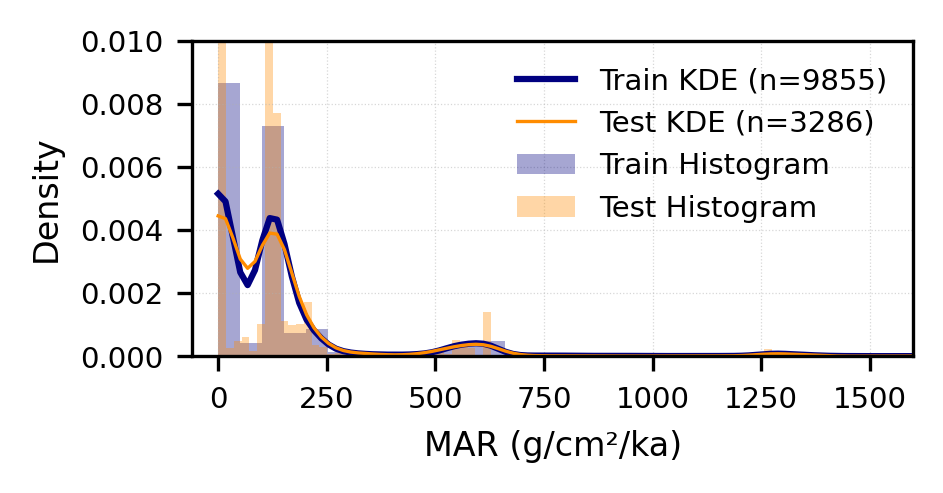

In [6]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(3, 1.5), dpi=300)

# KDE for train and test labels
kde_train = gaussian_kde(train_labels)
kde_test = gaussian_kde(test_labels)
x_min = min(np.min(train_labels), np.min(test_labels))
x_max = max(np.max(train_labels), np.max(test_labels))
x_range = np.linspace(x_min, x_max, 300)

# Plot KDEs
l1, = ax.plot(x_range, kde_train(x_range), label=f'Train KDE (n={len(train_labels)})', color='navy', lw=1.5, alpha=1)
l2, = ax.plot(x_range, kde_test(x_range), label=f'Test KDE (n={len(test_labels)})', color='darkorange', lw=0.8, alpha=1)

# Make histogram bars thinner using 'histtype="stepfilled"' and 'rwidth' < 1
hist_train = ax.hist(
    train_labels, 
    bins=100, 
    density=True, 
    alpha=0.35, 
    color='navy', 
    edgecolor='none', 
    label='Train Histogram',
    histtype='stepfilled',
    rwidth=0.2   # 0.2 makes the bars very thin
)
hist_test = ax.hist(
    test_labels, 
    bins=100, 
    density=True, 
    alpha=0.35, 
    color='darkorange', 
    edgecolor='none', 
    label='Test Histogram',
    histtype='stepfilled',
    rwidth=0.2
)

# Legend: add patches for histogram shading
hist_patches = [
    Patch(facecolor='navy', alpha=0.35, label='Train Histogram'),
    Patch(facecolor='darkorange', alpha=0.35, label='Test Histogram')
]

ax.set_xlim(left=-60, right=1600)
ax.set_ylim(0, 0.01)

ax.set_xlabel('MAR (g/cm²/ka)', fontsize=8)
ax.set_ylabel('Density', fontsize=8)
ax.tick_params(axis='both', which='major', labelsize=7)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%.0f'))
ax.yaxis.set_major_locator(mtick.MaxNLocator(nbins=5))
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.3f'))

# Build joint legend for KDE lines and histogram shadings
legend_handles = [l1, l2] + hist_patches
ax.legend(handles=legend_handles, frameon=False, fontsize=7, loc='upper right')

ax.grid(True, which='major', ls=':', lw=0.3, alpha=0.5)

plt.tight_layout(pad=0.2)
plt.show()


Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.


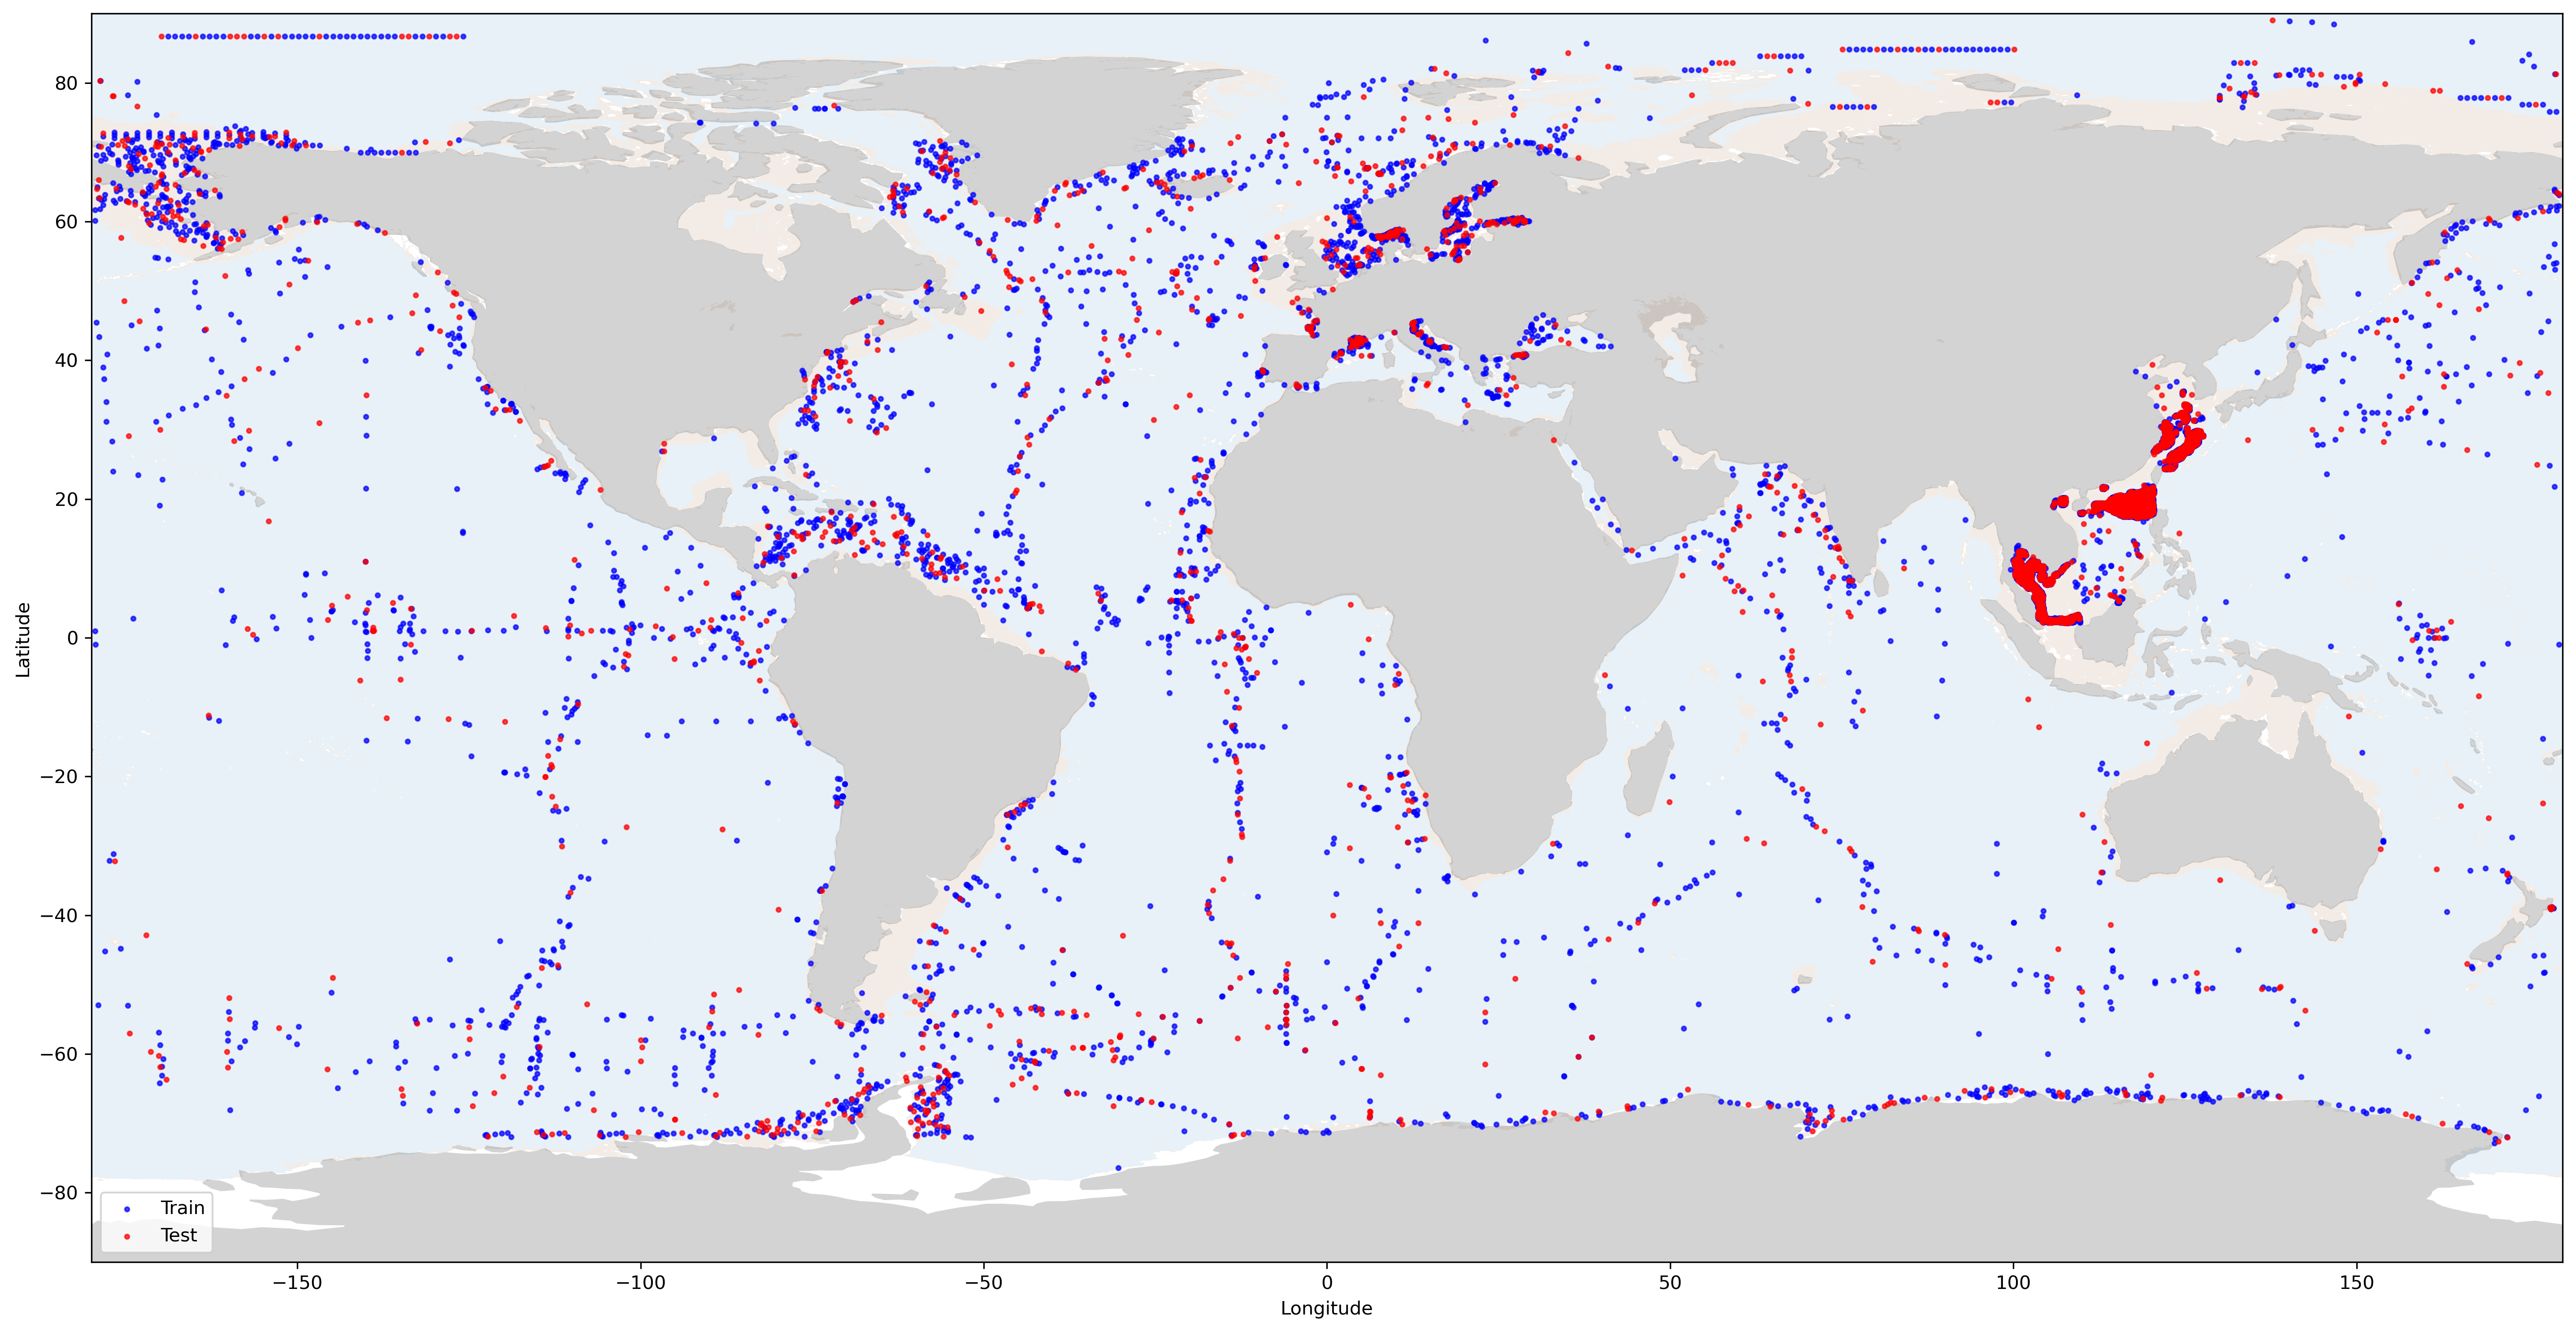

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

# Prepare training and testing coordinates and labels
train_lats = np.concatenate([train_lats_CS, train_lats_DO])
train_lons = np.concatenate([train_lons_CS, train_lons_DO])
test_lats = np.concatenate([test_lats_CS, test_lats_DO])
test_lons = np.concatenate([test_lons_CS, test_lons_DO])

train_labels_plot = np.concatenate([train_labels_CS, train_labels_DO])
test_labels_plot = np.concatenate([test_labels_CS, test_labels_DO])

# Create GeoDataFrames for train and test
train_gdf = gpd.GeoDataFrame({
    'label': train_labels_plot,
    'dataset': 'train'
}, geometry=[Point(lon, lat) for lon, lat in zip(train_lons, train_lats)], crs="EPSG:4326")

test_gdf = gpd.GeoDataFrame({
    'label': test_labels_plot,
    'dataset': 'test'
}, geometry=[Point(lon, lat) for lon, lat in zip(test_lons, test_lats)], crs="EPSG:4326")

# Combine for plotting
all_gdf = pd.concat([train_gdf, test_gdf], ignore_index=True)

# --- Overlay bathymetry regions: deep ocean (<-200m, blue) and shelf (-200m to 0m, brown) ---

restrepo_features_path = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated"
etopo_file = Path(restrepo_features_path) / "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"

# Try to load the bathymetry data and plot the regions
bathymetry_plotted = False
try:
    etopo_ds = xr.open_dataset(etopo_file, format='NETCDF4')
    # Find the elevation variable
    elev_var = [v for v in etopo_ds.data_vars if 'elev' in v.lower() or v.lower() in ['z', 'elevation']]
    if elev_var:
        elev = etopo_ds[elev_var[0]]
    else:
        elev = list(etopo_ds.data_vars.values())[0]  # fallback to first variable

    # Get lat/lon grid
    lat_vals = etopo_ds['lat'].values
    lon_vals = etopo_ds['lon'].values

    # Make meshgrid for plotting
    lon_grid, lat_grid = np.meshgrid(lon_vals, lat_vals)
    elev_grid = elev.values

    # Mask for deep ocean (<-200m) and shelf (-200m to 0m)
    deep_ocean_mask = elev_grid < -200
    shelf_mask = (elev_grid >= -200) & (elev_grid < 0)

    # --- FIX: Use correct colormap for shelf region ---
    # The issue is that pcolormesh with color='saddlebrown' and a boolean mask
    # will color all "True" as brown, but "False" as brown as well if not using a colormap.
    # Instead, use cmap with a ListedColormap for shelf, and mask out non-shelf.

    from matplotlib.colors import ListedColormap

    fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
    # Plot world basemap
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world.plot(ax=ax, color='lightgray', edgecolor='lightgray')

    # Plot deep ocean region (blue, transparent)
    ax.pcolormesh(
        lon_grid, lat_grid, np.where(deep_ocean_mask, 1, np.nan),
        cmap=ListedColormap(['#1f77b4']),  # blue
        alpha=0.1, shading='auto'
    )

    # Plot shelf region (brown, transparent)
    ax.pcolormesh(
        lon_grid, lat_grid, np.where(shelf_mask, 1, np.nan),
        cmap=ListedColormap(['saddlebrown']),
        alpha=0.1, shading='auto'
    )

    # Plot training and testing points
    train_gdf.plot(ax=ax, marker='o', color='blue', markersize=5, label='Train', alpha=0.7)
    test_gdf.plot(ax=ax, marker='o', color='red', markersize=5, label='Test', alpha=0.7)

    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.legend()
    plt.tight_layout()
    plt.show()
    bathymetry_plotted = True
except Exception as e:
    print(f"Could not plot bathymetry regions: {e}")

if not bathymetry_plotted:
    # Fallback: just plot the points and world map
    fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world.plot(ax=ax, color='lightgray', edgecolor='lightgray')
    train_gdf.plot(ax=ax, marker='o', color='blue', markersize=5, label='Train', alpha=0.7)
    test_gdf.plot(ax=ax, marker='o', color='red', markersize=5, label='Test', alpha=0.7)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.legend()
    plt.tight_layout()
    plt.show()


The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.


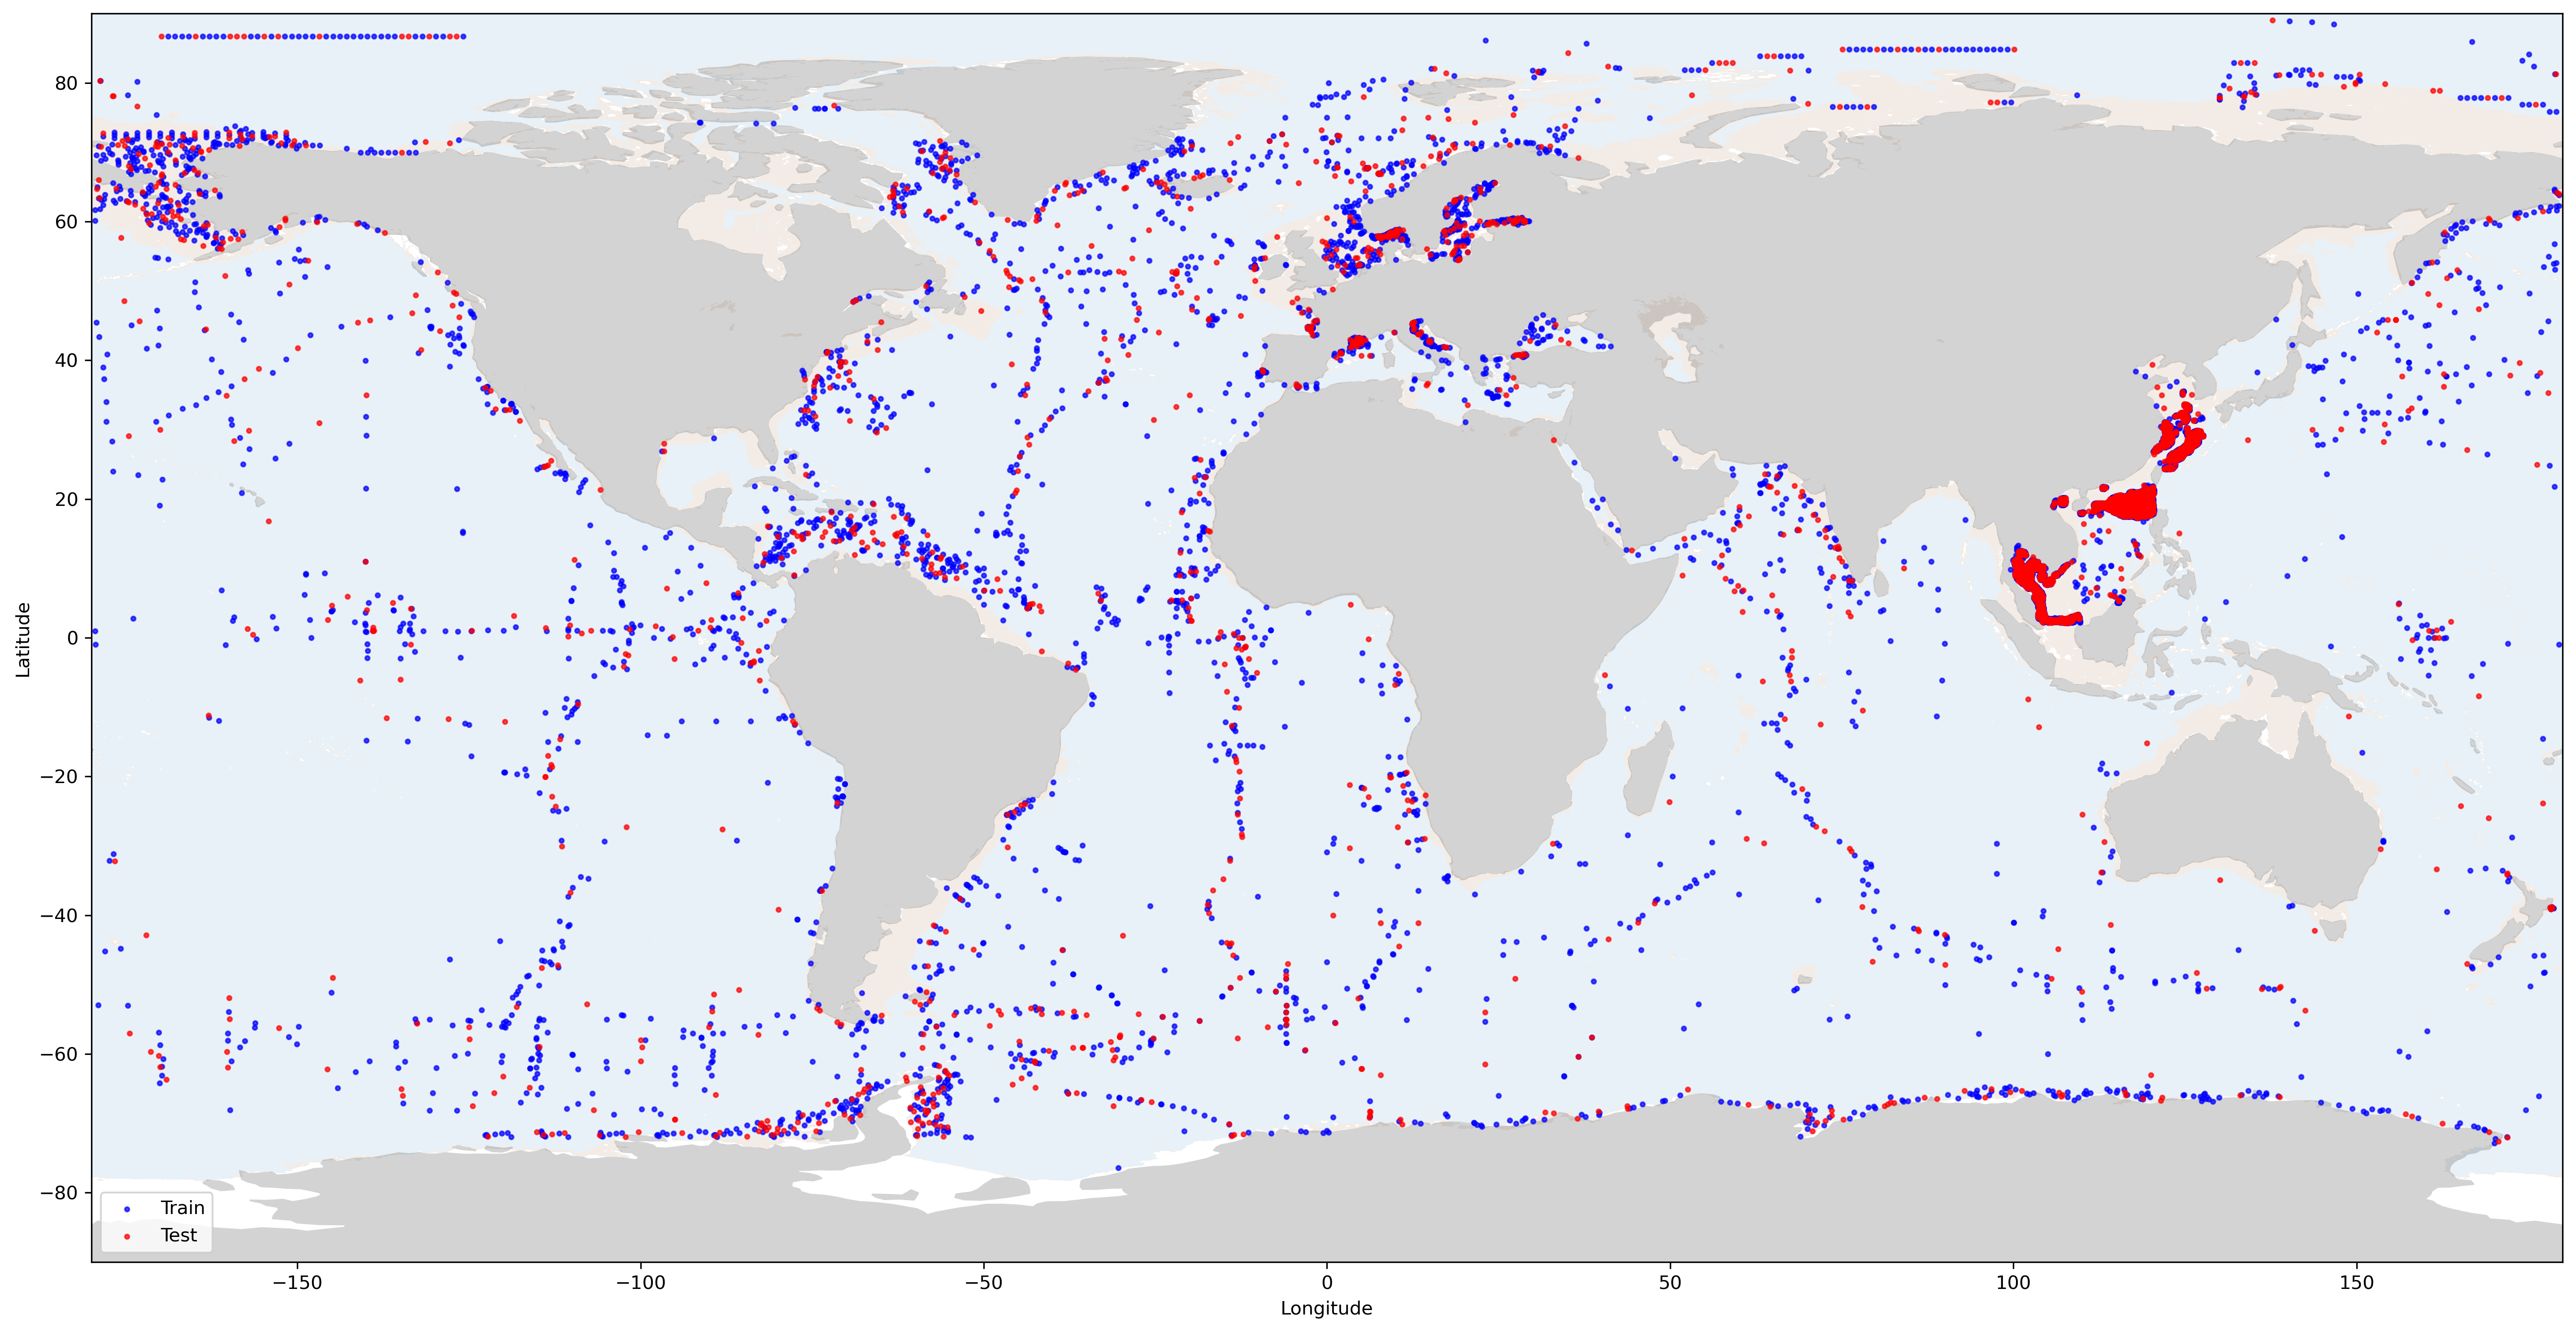

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

# Prepare training and testing coordinates and labels
train_lats = np.concatenate([train_lats_CS, train_lats_DO])
train_lons = np.concatenate([train_lons_CS, train_lons_DO])
test_lats = np.concatenate([test_lats_CS, test_lats_DO])
test_lons = np.concatenate([test_lons_CS, test_lons_DO])

train_labels_plot = np.concatenate([train_labels_CS, train_labels_DO])
test_labels_plot = np.concatenate([test_labels_CS, test_labels_DO])

# Create GeoDataFrames for train and test
train_gdf = gpd.GeoDataFrame({
    'label': train_labels_plot,
    'dataset': 'train'
}, geometry=[Point(lon, lat) for lon, lat in zip(train_lons, train_lats)], crs="EPSG:4326")

test_gdf = gpd.GeoDataFrame({
    'label': test_labels_plot,
    'dataset': 'test'
}, geometry=[Point(lon, lat) for lon, lat in zip(test_lons, test_lats)], crs="EPSG:4326")

# Combine for plotting
all_gdf = pd.concat([train_gdf, test_gdf], ignore_index=True)

# --- Overlay bathymetry regions: deep ocean (<-200m, blue) and shelf (-200m to 0m, brown) ---

restrepo_features_path = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated"
etopo_file = Path(restrepo_features_path) / "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd"

# Try to load the bathymetry data and plot the regions
bathymetry_plotted = False
try:
    etopo_ds = xr.open_dataset(etopo_file, format='NETCDF4')
    # Find the elevation variable
    elev_var = [v for v in etopo_ds.data_vars if 'elev' in v.lower() or v.lower() in ['z', 'elevation']]
    if elev_var:
        elev = etopo_ds[elev_var[0]]
    else:
        elev = list(etopo_ds.data_vars.values())[0]  # fallback to first variable

    # Get lat/lon grid
    lat_vals = etopo_ds['lat'].values
    lon_vals = etopo_ds['lon'].values

    # Make meshgrid for plotting
    lon_grid, lat_grid = np.meshgrid(lon_vals, lat_vals)
    elev_grid = elev.values

    # Mask for deep ocean (<-200m) and shelf (-200m to 0m)
    deep_ocean_mask = elev_grid < -200
    shelf_mask = (elev_grid >= -200) & (elev_grid < 0)

    # --- FIX: Use correct colormap for shelf region ---
    # The issue is that pcolormesh with color='saddlebrown' and a boolean mask
    # will color all "True" as brown, but "False" as brown as well if not using a colormap.
    # Instead, use cmap with a ListedColormap for shelf, and mask out non-shelf.

    from matplotlib.colors import ListedColormap

    fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
    # Plot world basemap
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world.plot(ax=ax, color='lightgray', edgecolor='lightgray')

    # Plot deep ocean region (blue, transparent)
    ax.pcolormesh(
        lon_grid, lat_grid, np.where(deep_ocean_mask, 1, np.nan),
        cmap=ListedColormap(['#1f77b4']),  # blue
        alpha=0.1, shading='auto'
    )

    # Plot shelf region (brown, transparent)
    ax.pcolormesh(
        lon_grid, lat_grid, np.where(shelf_mask, 1, np.nan),
        cmap=ListedColormap(['saddlebrown']),
        alpha=0.1, shading='auto'
    )

    # Plot training and testing points
    train_gdf.plot(ax=ax, marker='o', color='blue', markersize=5, label='Train', alpha=0.7)
    test_gdf.plot(ax=ax, marker='o', color='red', markersize=5, label='Test', alpha=0.7)

    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.legend()
    plt.tight_layout()
    plt.show()
    bathymetry_plotted = True
except Exception as e:
    print(f"Could not plot bathymetry regions: {e}")

if not bathymetry_plotted:
    # Fallback: just plot the points and world map
    fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world.plot(ax=ax, color='lightgray', edgecolor='lightgray')
    train_gdf.plot(ax=ax, marker='o', color='blue', markersize=5, label='Train', alpha=0.7)
    test_gdf.plot(ax=ax, marker='o', color='red', markersize=5, label='Test', alpha=0.7)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.legend()
    plt.tight_layout()
    plt.show()


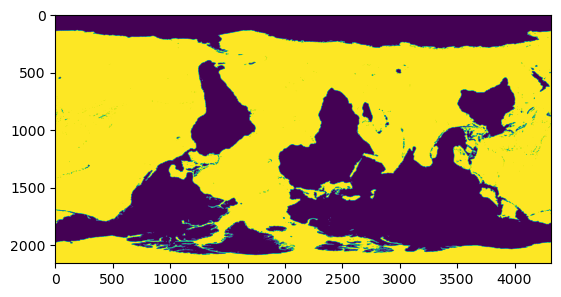

In [9]:
plt.imshow(deep_ocean_mask)

In [ ]:
num_trees = np.concatenate([np.linspace(0,10, 11, dtype = int)[1:], np.linspace(0, 100, 11, dtype = int)[2:], np.linspace(0, 1000, 11, dtype = int)[2:]])

Random Forest with 1 trees
Train MAE: 9.3312
Train Correlation: 0.9121
Train R2: 0.8320
Test MAE: 26.1424
Test Correlation: 0.7963
Test R2: 0.6340
Random Forest with 2 trees
Train MAE: 9.2320
Train Correlation: 0.9492
Train R2: 0.9011
Test MAE: 23.5952
Test Correlation: 0.8777
Test R2: 0.7704
Random Forest with 3 trees
Train MAE: 9.0948
Train Correlation: 0.9604
Train R2: 0.9224
Test MAE: 21.3788
Test Correlation: 0.9063
Test R2: 0.8214
Random Forest with 4 trees
Train MAE: 9.0774
Train Correlation: 0.9646
Train R2: 0.9304
Test MAE: 20.5822
Test Correlation: 0.9148
Test R2: 0.8369
Random Forest with 5 trees
Train MAE: 8.8850
Train Correlation: 0.9705
Train R2: 0.9418
Test MAE: 19.8993
Test Correlation: 0.9209
Test R2: 0.8480
Random Forest with 6 trees
Train MAE: 8.5684
Train Correlation: 0.9721
Train R2: 0.9449
Test MAE: 19.5094
Test Correlation: 0.9253
Test R2: 0.8562
Random Forest with 7 trees
Train MAE: 8.5067
Train Correlation: 0.9766
Train R2: 0.9537
Test MAE: 19.6573
Test Correla

Train MAE: 8.0144
Train Correlation: 0.9861
Train R2: 0.9724
Test MAE: 19.4328
Test Correlation: 0.9273
Test R2: 0.8598
Random Forest with 40 trees
Train MAE: 7.9446
Train Correlation: 0.9865
Train R2: 0.9731
Test MAE: 19.2455
Test Correlation: 0.9300
Test R2: 0.8649
Random Forest with 50 trees
Train MAE: 7.9765
Train Correlation: 0.9864
Train R2: 0.9731
Test MAE: 19.1325
Test Correlation: 0.9320
Test R2: 0.8687
Random Forest with 60 trees
Train MAE: 7.9111
Train Correlation: 0.9866
Train R2: 0.9733
Test MAE: 18.9314
Test Correlation: 0.9324
Test R2: 0.8693
Random Forest with 70 trees
Train MAE: 7.9000
Train Correlation: 0.9865
Train R2: 0.9731
Test MAE: 19.0632
Test Correlation: 0.9309
Test R2: 0.8665
Random Forest with 80 trees
Train MAE: 7.9031
Train Correlation: 0.9869
Train R2: 0.9739
Test MAE: 19.2300
Test Correlation: 0.9295
Test R2: 0.8640
Random Forest with 90 trees
Train MAE: 7.9056
Train Correlation: 0.9869
Train R2: 0.9741
Test MAE: 19.3399
Test Correlation: 0.9286
Test R2:

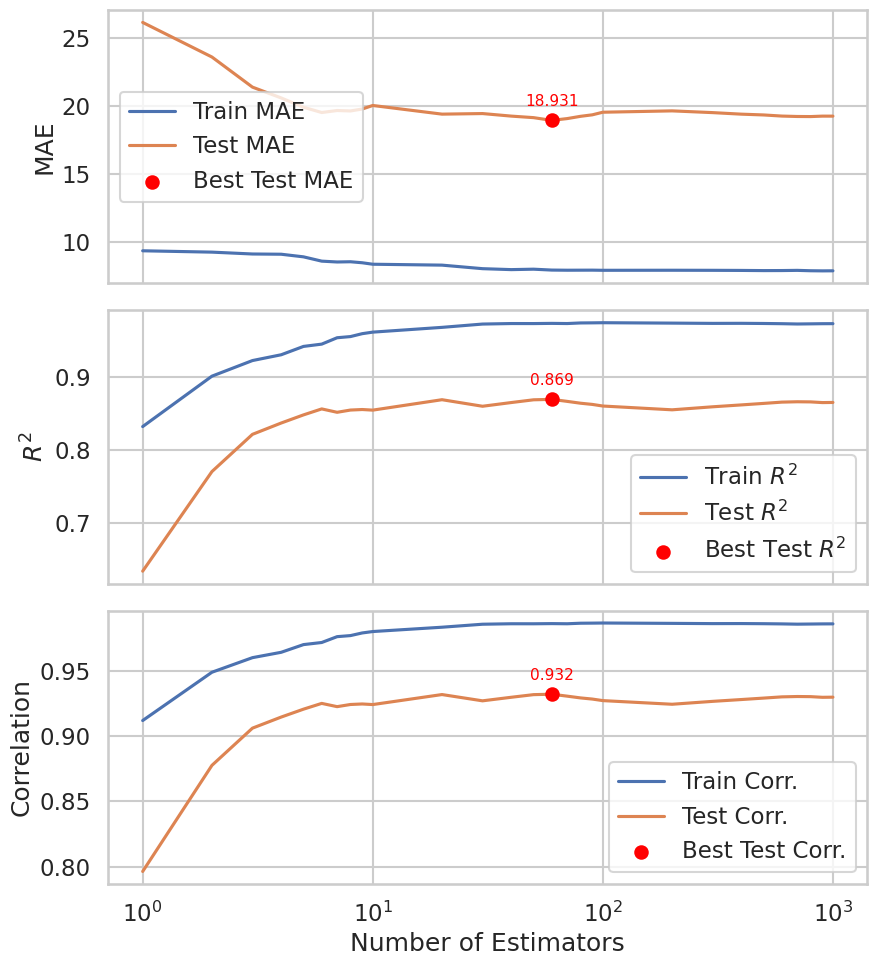

In [24]:
n_estimators_list = []
train_mae_list = []
test_mae_list = []
train_r2_list = []
test_r2_list = []
train_corr_list = []
test_corr_list = []

# Loop over n_estimators
for n_estimators in num_trees:
    print("="*80)
    print(f"Random Forest with {n_estimators} trees")
    
    # Train and evaluate
    model, training_mae, evaluation_mae, train_predictions, test_predictions = train_tree_based_model(
        train_features, train_labels, test_features, test_labels,
        n_estimators=n_estimators
    )
    # Collect performance metrics
    n_estimators_list.append(n_estimators)

    train_mae, train_corr, train_r2 = create_scatter_plot(train_labels, train_predictions, "dummy_train.png")
    test_mae, test_corr, test_r2 = create_scatter_plot(test_labels, test_predictions, "dummy_test.png")
    print(f"Train MAE: {train_mae:.4f}")
    print(f"Train Correlation: {train_corr:.4f}")
    print(f"Train R2: {train_r2:.4f}")
    print(f"Test MAE: {test_mae:.4f}")
    print(f"Test Correlation: {test_corr:.4f}")
    print(f"Test R2: {test_r2:.4f}")
    train_mae_list.append(train_mae)
    test_mae_list.append(test_mae)
    train_r2_list.append(train_r2)
    test_r2_list.append(test_r2)
    train_corr_list.append(train_corr)
    test_corr_list.append(test_corr)


plot_tree_model_performance(
    n_estimators_list,
    train_mae_list, test_mae_list,
    train_r2_list, test_r2_list,
    train_corr_list, test_corr_list
)

XGBoost with 1 trees
Train MAE: 109.4283
Train Correlation: 0.8807
Train R2: 0.7756
Test MAE: 108.8869
Test Correlation: 0.8907
Test R2: 0.7934
XGBoost with 2 trees
Train MAE: 108.5693
Train Correlation: 0.8821
Train R2: 0.7780
Test MAE: 108.0150
Test Correlation: 0.8915
Test R2: 0.7948
XGBoost with 3 trees
Train MAE: 107.7178
Train Correlation: 0.8836
Train R2: 0.7807
Test MAE: 107.1537
Test Correlation: 0.8928
Test R2: 0.7972
XGBoost with 4 trees


Train MAE: 106.8705
Train Correlation: 0.8870
Train R2: 0.7867
Test MAE: 106.2985
Test Correlation: 0.8973
Test R2: 0.8052
XGBoost with 5 trees
Train MAE: 106.0310
Train Correlation: 0.8883
Train R2: 0.7891
Test MAE: 105.4532
Test Correlation: 0.8981
Test R2: 0.8066
XGBoost with 6 trees
Train MAE: 105.2071
Train Correlation: 0.8881
Train R2: 0.7887
Test MAE: 104.6274
Test Correlation: 0.8975
Test R2: 0.8055
XGBoost with 7 trees
Train MAE: 104.3870
Train Correlation: 0.8891
Train R2: 0.7905
Test MAE: 103.8035
Test Correlation: 0.8973
Test R2: 0.8051
XGBoost with 8 trees
Train MAE: 103.5829
Train Correlation: 0.8890
Train R2: 0.7903
Test MAE: 102.9948
Test Correlation: 0.8973
Test R2: 0.8051
XGBoost with 9 trees
Train MAE: 102.7816
Train Correlation: 0.8894
Train R2: 0.7911
Test MAE: 102.1881
Test Correlation: 0.8970
Test R2: 0.8046
XGBoost with 10 trees
Train MAE: 101.9946
Train Correlation: 0.8903
Train R2: 0.7926
Test MAE: 101.3980
Test Correlation: 0.8965
Test R2: 0.8038
XGBoost with

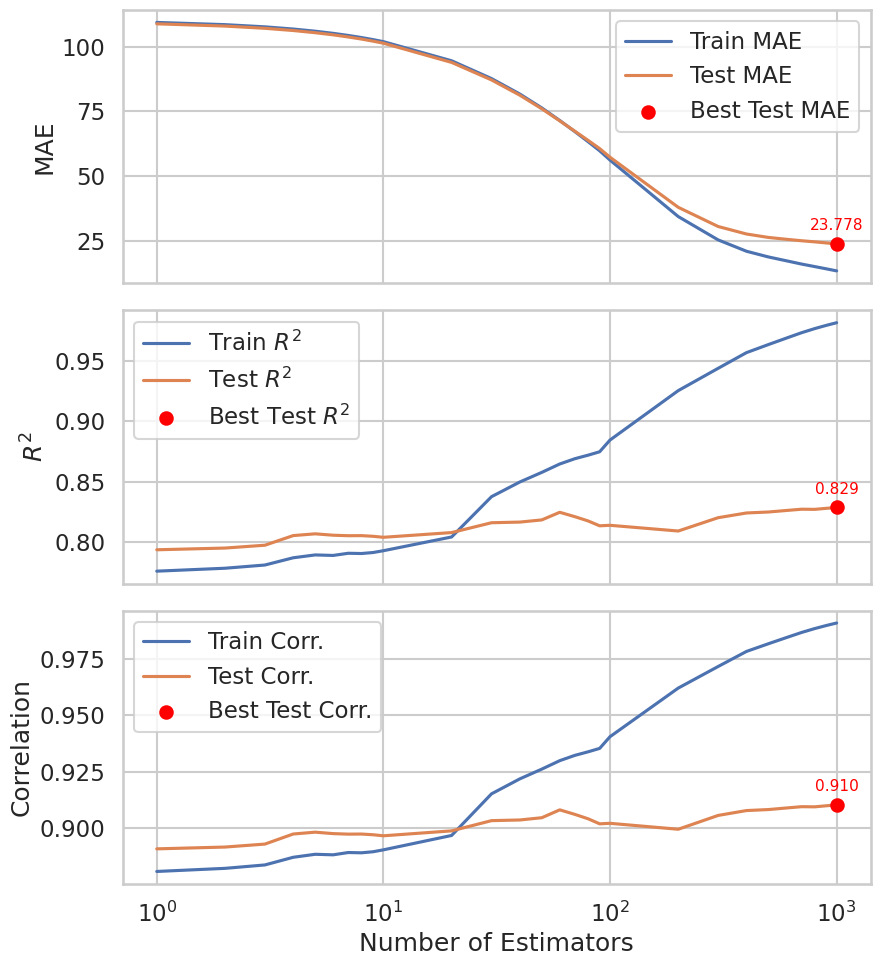

In [25]:

#set_seed(42)
model_type = "xgboost"
n_estimators_list = []
train_mae_list = []
test_mae_list = []
train_r2_list = []
test_r2_list = []
train_corr_list = []
test_corr_list = []


# Loop over n_estimators
for n_estimators in num_trees:
    set_seed(42)
    print("="*80)
    print(f"XGBoost with {n_estimators} trees")
    model, training_mae, evaluation_mae, train_predictions, test_predictions = train_tree_based_model(
        train_features, train_labels, test_features, test_labels,
        model_type=model_type, 
        n_estimators=n_estimators
    )
    # Collect performance metrics
    n_estimators_list.append(n_estimators)
    train_mae, train_corr, train_r2 = create_scatter_plot(train_labels, train_predictions, "dummy_train.png")
    test_mae, test_corr, test_r2 = create_scatter_plot(test_labels, test_predictions, "dummy_test.png")
    print(f"Train MAE: {train_mae:.4f}")
    print(f"Train Correlation: {train_corr:.4f}")
    print(f"Train R2: {train_r2:.4f}")
    print(f"Test MAE: {test_mae:.4f}")
    print(f"Test Correlation: {test_corr:.4f}")
    print(f"Test R2: {test_r2:.4f}")
    train_mae_list.append(train_mae)
    test_mae_list.append(test_mae)
    train_r2_list.append(train_r2)
    test_r2_list.append(test_r2)
    train_corr_list.append(train_corr)
    test_corr_list.append(test_corr)


plot_tree_model_performance(
    n_estimators_list,
    train_mae_list, test_mae_list,
    train_r2_list, test_r2_list,
    train_corr_list, test_corr_list
)

CatBoost with 1 trees


Train MAE: 109.6170
Train Correlation: 0.7498
Train R2: 0.5622
Test MAE: 109.0627
Test Correlation: 0.7983
Test R2: 0.6373
CatBoost with 2 trees
Train MAE: 108.9219
Train Correlation: 0.7702
Train R2: 0.5932
Test MAE: 108.3508
Test Correlation: 0.8120
Test R2: 0.6593
CatBoost with 3 trees
Train MAE: 108.2394
Train Correlation: 0.7834
Train R2: 0.6137
Test MAE: 107.6535
Test Correlation: 0.8364
Test R2: 0.6995
CatBoost with 4 trees
Train MAE: 107.5797
Train Correlation: 0.7878
Train R2: 0.6206
Test MAE: 106.9689
Test Correlation: 0.8366
Test R2: 0.6999
CatBoost with 5 trees
Train MAE: 106.9488
Train Correlation: 0.8023
Train R2: 0.6437
Test MAE: 106.3188
Test Correlation: 0.8466
Test R2: 0.7167
CatBoost with 6 trees
Train MAE: 106.3143
Train Correlation: 0.8132
Train R2: 0.6614
Test MAE: 105.6993
Test Correlation: 0.8563
Test R2: 0.7332
CatBoost with 7 trees
Train MAE: 105.6735
Train Correlation: 0.8160
Train R2: 0.6658
Test MAE: 105.0327
Test Correlation: 0.8538
Test R2: 0.7289
CatBoos

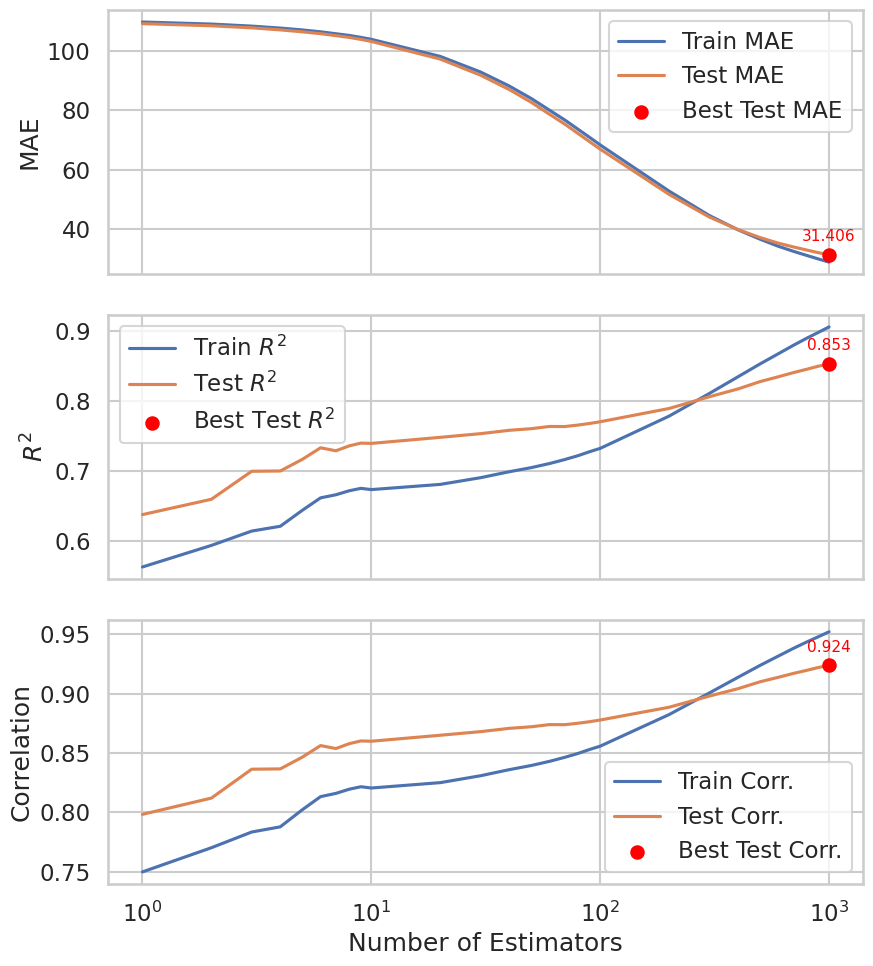

In [26]:
# To store results
set_seed(42)
model_type = "catboost"
n_estimators_list = []
train_mae_list = []
test_mae_list = []
train_r2_list = []
test_r2_list = []
train_corr_list = []
test_corr_list = []


# Loop over n_estimators
for n_estimators in num_trees:
    set_seed(42)
    print("="*80)
    print(f"CatBoost with {n_estimators} trees")
    model, training_mae, evaluation_mae, train_predictions, test_predictions = train_tree_based_model(
        train_features, train_labels, test_features, test_labels,
        model_type=model_type, 
        n_estimators=n_estimators)
    # Collect performance metrics
    n_estimators_list.append(n_estimators)

    train_mae, train_corr, train_r2 = create_scatter_plot(train_labels, train_predictions, "dummy_train.png")
    test_mae, test_corr, test_r2 = create_scatter_plot(test_labels, test_predictions, "dummy_test.png")
    print(f"Train MAE: {train_mae:.4f}")
    print(f"Train Correlation: {train_corr:.4f}")
    print(f"Train R2: {train_r2:.4f}")
    print(f"Test MAE: {test_mae:.4f}")
    print(f"Test Correlation: {test_corr:.4f}")
    print(f"Test R2: {test_r2:.4f}")
    train_mae_list.append(train_mae)
    test_mae_list.append(test_mae)
    train_r2_list.append(train_r2)
    test_r2_list.append(test_r2)
    train_corr_list.append(train_corr)
    test_corr_list.append(test_corr)



plot_tree_model_performance(
    n_estimators_list,
    train_mae_list, test_mae_list,
    train_r2_list, test_r2_list,
    train_corr_list, test_corr_list
)

## TABPFN

In [27]:
# Assuming there is a TabPFNRegressor (if not, a different regressor should be used)
# Assuming there is a TabPFNRegressor (if not, a different regressor should be used)
from tabpfn import TabPFNRegressor  
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
# Load Boston Housing data
from sklearn.datasets import make_regression
import pandas as pd


# Initialize the regressor
regressor = TabPFNRegressor()  
regressor.fit(train_features, train_labels)

# Predict on the test set
predictions = regressor.predict(test_features)

# Evaluate the model
mse = mean_squared_error(test_labels, predictions)
r2 = r2_score(test_labels, predictions)

print("Mean Squared Error (MSE):", mse)

KeyboardInterrupt: 

In [ ]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Predictions
y_train_pred = regressor.predict(train_features)
y_test_pred = predictions  # Assuming this is regressor.predict(X_test)

# Train metrics
train_mae = mean_absolute_error(train_labels, y_train_pred)
train_corr = np.corrcoef(train_labels, y_train_pred)[0, 1]

# Test metrics
test_mae = mean_absolute_error(test_labels, y_test_pred)
test_corr = np.corrcoef(test_labels, y_test_pred)[0, 1]

# Print metrics
print(f"Train MAE: {train_mae:.4f}")
print(f"Train Correlation: {train_corr:.4f}")
print(f"Test MAE: {test_mae:.4f}")
print(f"Test Correlation: {test_corr:.4f}")


In [ ]:
# Plotting the results
plt.figure(figsize=(10, 6))

# Scatter plot for training data
plt.scatter(train_labels, regressor.predict(train_features), color='blue', label='Train', alpha=0.7)
# Scatter plot for test data
plt.scatter(test_labels, predictions, color='red', label='Test', alpha=0.7)

# Calculate and display the correlation coefficient
correlation = np.corrcoef(test_labels, predictions)[0, 1]
plt.text(0.1, 0.9, f'Correlation: {correlation:.2f}', transform=plt.gca().transAxes, fontsize=12)

plt.title('TabPFN: Predicted vs. Actual Values')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from os import walk  
feature_path = Path(Path() / str(project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_Sedrate_DO_men"))
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)


first_run = True
ii = 0
features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)


    # Perform multiple forward passes with dropout
    num_samples = 5  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    with torch.no_grad():
        for i in range(num_samples):
            predictions = regressor.predict(features) #decoded, 

            # Store predictions for later averaging
            predictions_sum[i] = predictions.reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

    ii += 1
    print("Prediction " + str(ii) + " done!")

#del features
gc.collect()

land_file = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
prediction_map2[land_map] = 0
plt.imshow(prediction_map2 , vmin = 0, vmax = 1000, cmap="cubehelix")
cbar = plt.colorbar()
#"""

#np.save(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_SedRate_DO_catboost"), prediction_map2)

## K Nearest Neighbours

In [6]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import numpy as np

def train_knn(features_train, labels_train, features_test, labels_test, n_neighbors=5):
    # Initialize the model
    model = KNeighborsRegressor(
        n_neighbors=n_neighbors,
        weights='uniform',
        metric='minkowski',
        p=2
    )
    
    # Train the model
    model.fit(features_train, labels_train)
    
    # Evaluate on training set
    train_predictions = model.predict(features_train)
    train_mae = mean_absolute_error(labels_train, train_predictions)
    
    # Evaluate on test set
    test_predictions = model.predict(features_test)
    test_mae = mean_absolute_error(labels_test, test_predictions)
    
    return model, train_mae, test_mae, train_predictions, test_predictions

KNN with k=1 neighbors
Train MAE: 0.0000
Train Correlation: 1.0000
Train R2: 1.0000
Test MAE: 20.4354
Test Correlation: 0.7796
Test R2: 0.5153
KNN with k=2 neighbors
Train MAE: 10.3905
Train Correlation: 0.9567
Train R2: 0.9152
Test MAE: 18.3219
Test Correlation: 0.8724
Test R2: 0.7483
KNN with k=3 neighbors
Train MAE: 13.9961
Train Correlation: 0.9336
Train R2: 0.8713
Test MAE: 18.5662
Test Correlation: 0.8937
Test R2: 0.7937
KNN with k=4 neighbors
Train MAE: 15.7979
Train Correlation: 0.9219
Train R2: 0.8494
Test MAE: 18.6843
Test Correlation: 0.9018
Test R2: 0.8109
KNN with k=5 neighbors
Train MAE: 17.4544
Train Correlation: 0.9098
Train R2: 0.8273
Test MAE: 19.2692
Test Correlation: 0.9058
Test R2: 0.8188
KNN with k=6 neighbors
Train MAE: 18.6663
Train Correlation: 0.9019
Train R2: 0.8131
Test MAE: 19.8547
Test Correlation: 0.9078
Test R2: 0.8234
KNN with k=7 neighbors
Train MAE: 19.4886
Train Correlation: 0.8955
Train R2: 0.8014
Test MAE: 20.4865
Test Correlation: 0.9095
Test R2: 

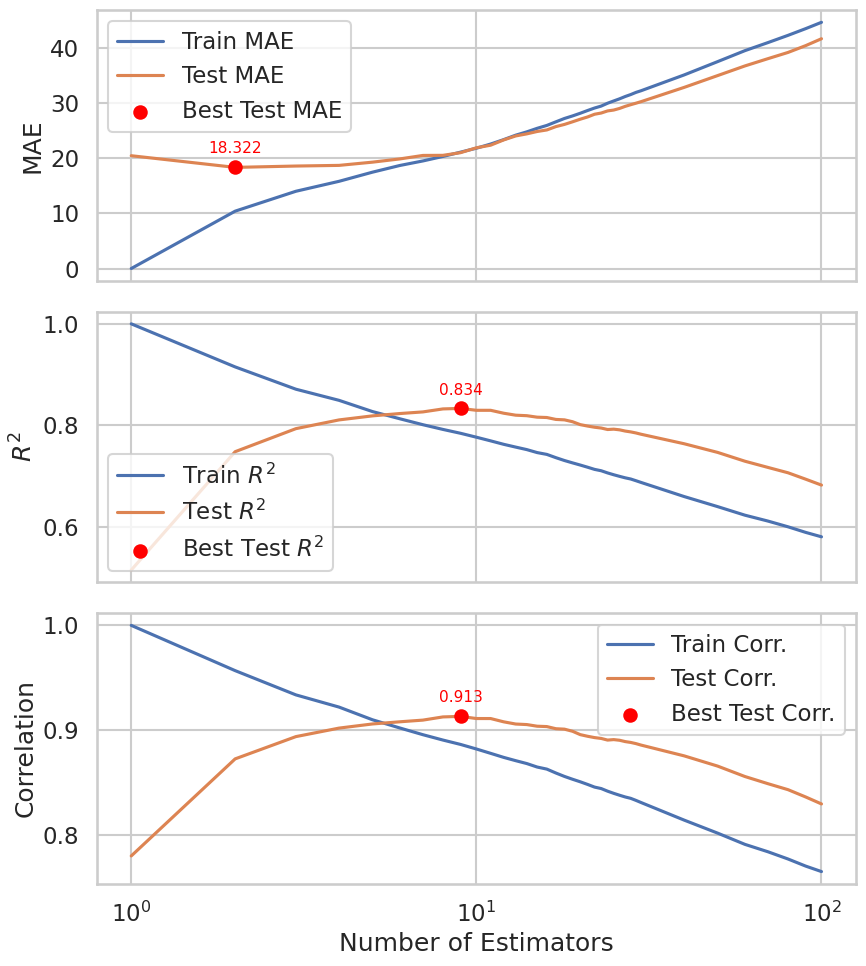

In [9]:
# Store results
set_seed(42)
k_values = []
train_mae_list = []
test_mae_list = []
train_r2_list = []
test_r2_list = []
train_corr_list = []
test_corr_list = []

# Values of k to evaluate
k_range = list(range(1, 31)) + list(range(40, 101, 10))  # 1–30, then 40–100 step 10

for k in k_range:
    print("="*80)
    print(f"KNN with k={k} neighbors")

    # Train and evaluate
    model, training_mae, evaluation_mae, train_predictions, test_predictions = train_knn(
        train_features, train_labels, test_features, test_labels,
        n_neighbors=k
    )

    # Compute metrics
    train_r2 = r2_score(train_labels, train_predictions)
    test_r2 = r2_score(test_labels, test_predictions)
    train_corr = np.corrcoef(train_labels.ravel(), train_predictions.ravel())[0, 1]
    test_corr = np.corrcoef(test_labels.ravel(), test_predictions.ravel())[0, 1]

    print(f"Train MAE: {training_mae:.4f}")
    print(f"Train Correlation: {train_corr:.4f}")
    print(f"Train R2: {train_r2:.4f}")
    print(f"Test MAE: {evaluation_mae:.4f}")
    print(f"Test Correlation: {test_corr:.4f}")
    print(f"Test R2: {test_r2:.4f}")

    # Store
    k_values.append(k)
    train_mae_list.append(training_mae)
    test_mae_list.append(evaluation_mae)
    train_r2_list.append(train_r2)
    test_r2_list.append(test_r2)
    train_corr_list.append(train_corr)
    test_corr_list.append(test_corr)


plot_tree_model_performance(
    k_values,
    train_mae_list, test_mae_list,
    train_r2_list, test_r2_list,
    train_corr_list, test_corr_list
)

## LightGBM


In [ ]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import numpy as np

def train_lgbm(features_train, labels_train, features_test, labels_test, 
               n_estimators=100, learning_rate=0.1, num_leaves=31, random_state=42):
    # Initialize the model
    model = LGBMRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        num_leaves=num_leaves,
        random_state=random_state
    )
    
    # Train the model
    model.fit(features_train, labels_train)
    
    # Evaluate on training set
    train_predictions = model.predict(features_train)
    train_mae = mean_absolute_error(labels_train, train_predictions)
    
    # Evaluate on test set
    test_predictions = model.predict(features_test)
    test_mae = mean_absolute_error(labels_test, test_predictions)
    
    return model, train_mae, test_mae, train_predictions, test_predictions

LightGBM with n_estimators=10
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007821 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067
Train MAE: 59.2398
Train Correlation: 0.9159
Train R2: 0.7165
Test MAE: 59.9690
Test Correlation: 0.9078
Test R2: 0.7313
LightGBM with n_estimators=20
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003004 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067
Train MAE: 38.1783
Train Correlation: 0.9313
Train R2: 0.8434
Test MAE: 41.4670
Test Correlation: 0.9131
Test R2: 0.8254
LightGBM

X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003529 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067
Train MAE: 29.5184
Train Correlation: 0.9428
Train R2: 0.8815
Test MAE: 34.2815
Test Correlation: 0.9160
Test R2: 0.8389
LightGBM with n_estimators=40
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003005 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067
Train MAE: 25.9762
Train Correlation: 0.9512
Train R2: 0.9005
Test MAE: 31.9370
Test Correlation: 0.9180
Test R2: 0.8424
LightGBM with n_estimators=50
[LightGB

X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names


Train MAE: 23.8273
Train Correlation: 0.9570
Train R2: 0.9127
Test MAE: 30.8708
Test Correlation: 0.9193
Test R2: 0.8442
LightGBM with n_estimators=60
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002881 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067
Train MAE: 22.4078
Train Correlation: 0.9619
Train R2: 0.9225
Test MAE: 30.2394
Test Correlation: 0.9205
Test R2: 0.8460
LightGBM with n_estimators=70
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003146 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067


X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names


... (21 outputs left out)

X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names


Train MAE: 14.0272
Train Correlation: 0.9883
Train R2: 0.9757
Test MAE: 27.7635
Test Correlation: 0.9217
Test R2: 0.8462
LightGBM with n_estimators=200
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006344 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26515
[LightGBM] [Info] Number of data points in the train set: 9813, number of used features: 109
[LightGBM] [Info] Start training from score 134.652067


X does not have valid feature names, but LGBMRegressor was fitted with feature names
X does not have valid feature names, but LGBMRegressor was fitted with feature names


Train MAE: 13.6200
Train Correlation: 0.9892
Train R2: 0.9774
Test MAE: 27.6866
Test Correlation: 0.9217
Test R2: 0.8463


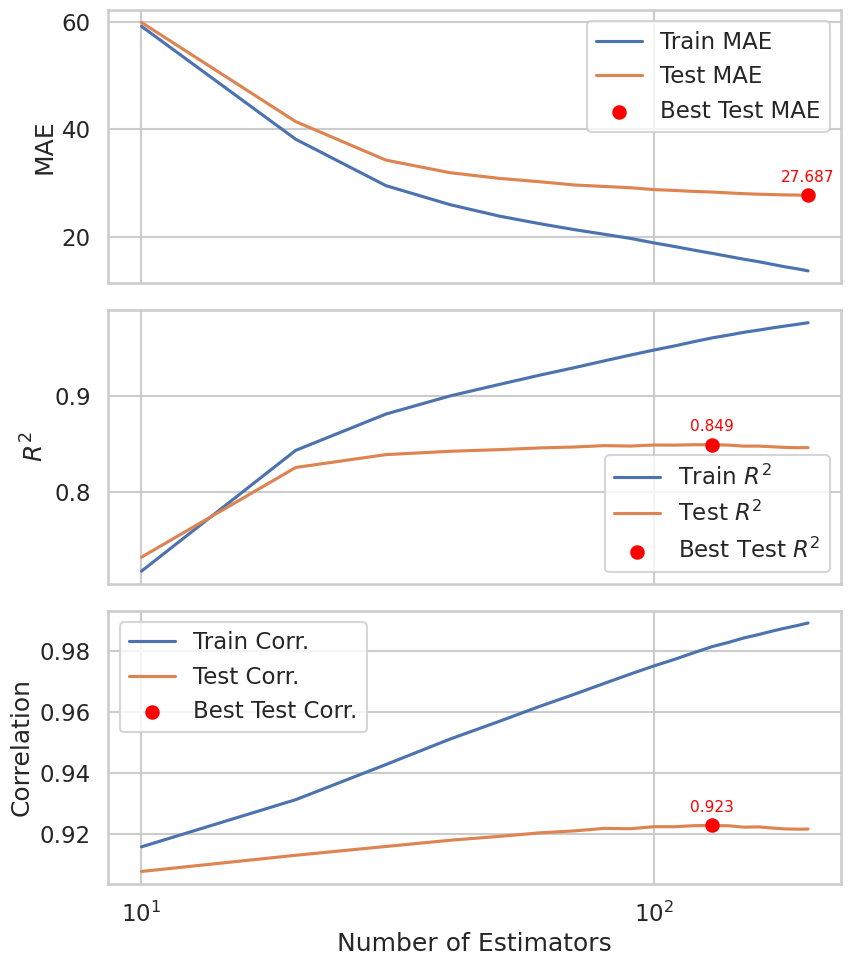

In [ ]:
# Store results for LightGBM
set_seed(42)
n_estimators_values = list(range(10, 201, 10))  # Try n_estimators from 10 to 200 step 10
train_mae_list = []
test_mae_list = []
train_r2_list = []
test_r2_list = []
train_corr_list = []
test_corr_list = []

for n_estimators in n_estimators_values:
    print("="*80)
    print(f"LightGBM with n_estimators={n_estimators}")

    # Train and evaluate
    model, training_mae, evaluation_mae, train_predictions, test_predictions = train_lgbm(
        train_features, train_labels, test_features, test_labels,
        n_estimators=n_estimators
    )

    # Compute metrics
    train_r2 = r2_score(train_labels, train_predictions)
    test_r2 = r2_score(test_labels, test_predictions)
    train_corr = np.corrcoef(train_labels.ravel(), train_predictions.ravel())[0, 1]
    test_corr = np.corrcoef(test_labels.ravel(), test_predictions.ravel())[0, 1]

    print(f"Train MAE: {training_mae:.4f}")
    print(f"Train Correlation: {train_corr:.4f}")
    print(f"Train R2: {train_r2:.4f}")
    print(f"Test MAE: {evaluation_mae:.4f}")
    print(f"Test Correlation: {test_corr:.4f}")
    print(f"Test R2: {test_r2:.4f}")

    # Store
    train_mae_list.append(training_mae)
    test_mae_list.append(evaluation_mae)
    train_r2_list.append(train_r2)
    test_r2_list.append(test_r2)
    train_corr_list.append(train_corr)
    test_corr_list.append(test_corr)

plot_tree_model_performance(
    n_estimators_values,
    train_mae_list, test_mae_list,
    train_r2_list, test_r2_list,
    train_corr_list, test_corr_list
)

## random forest

In [6]:
model, train_mae, test_mae, train_preds, test_preds = train_tree_based_model(
    train_features, train_labels, test_features, test_labels, n_estimators=60)

In [ ]:
def plot_predictions(y_train, train_preds, y_test, test_preds, model_name, n_estimators, save_path=None):
    # Calculate metrics
    train_mae = mean_absolute_error(y_train, train_preds)
    test_mae = mean_absolute_error(y_test, test_preds)
    train_corr = np.corrcoef(y_train, train_preds)[0, 1]
    test_corr = np.corrcoef(y_test, test_preds)[0, 1]
    
    # Calculate R² for additional information
    from sklearn.metrics import r2_score
    train_r2 = r2_score(y_train, train_preds)
    test_r2 = r2_score(y_test, test_preds)

    # Combine train and test for density plot
    all_true = np.concatenate([y_train, y_test])
    all_pred = np.concatenate([train_preds, test_preds])

    # Find the overall min and max for axis and binning
    min_lim = min(all_true.min(), all_pred.min())
    max_lim = max(all_true.max(), all_pred.max())

    # Clamp display axis at 1500 as maximum
    min_display = min_lim
    max_display = min(1500, max_lim)

    # Compact figure size for publication
    fig, ax = plt.subplots(figsize=(4.5, 4.5))

    # Use 2D histogram for density, limiting counts per bin to max 15
    counts, xedges, yedges, im = ax.hist2d(
        all_true, all_pred,
        bins=100,
        range=[[min_display, max_display], [min_display, max_display]],
        cmap='viridis',
        cmin=0, vmax=15
    )
    # Set up colorbar with larger text - make it shorter
    cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.75, aspect=20)
    cbar.set_label('Counts', fontsize=10, fontweight='bold', labelpad=5)
    cbar.ax.tick_params(labelsize=8)
    
    # Generate the colorbar ticks up to 15
    cbar_ticks = np.arange(0, 16, 3)
    if cbar_ticks[-1] != 15:
        cbar_ticks = np.append(cbar_ticks, 15)
    cbar.set_ticks(cbar_ticks)
    ticklabels = [f"{int(t)}" for t in cbar_ticks]
    if len(ticklabels) > 0:
        ticklabels[-1] = ">15"
    cbar.set_ticklabels(ticklabels)

    # Set specified grid values at 300, 600, 1200, 1500
    grid_values = [300, 600, 900, 1200, 1500]
    ax.set_xlim(min_display, max_display)
    ax.set_ylim(min_display, max_display)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks(grid_values)
    ax.set_yticks(grid_values)
    ax.tick_params(axis='both', labelsize=10)

    # 1:1 line with thicker line
    ax.plot([min_display, max_display], [min_display, max_display], 'k--', lw=2, alpha=0.8)
    
    # Axis labels with larger, bold text
    ax.set_xlabel('True Values (g cm⁻² ka⁻¹)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Predicted Values (g cm⁻² ka⁻¹)', fontsize=12, fontweight='bold')
    #plt.title(f"{model_name} Predictions (n_estimators={n_estimators:.0f})")

    # Place the statistics in a textbox with more information and larger text
    # Position adjusted to stay within plot boundaries
    textstr = (
        f"Train: MAE={train_mae:.2f}, R²={train_r2:.3f}, CC={train_corr:.3f}\n"
        f"Test:  MAE={test_mae:.2f}, R²={test_r2:.3f}, CC={test_corr:.3f}"
    )
    ax.text(0.05, 0.98, textstr, transform=ax.transAxes, fontsize=9, 
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', linewidth=1.0, boxstyle='round,pad=0.4'), 
            ha='left', va='top', fontweight='bold')
    
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
    plt.tight_layout(pad=0.5)
    
    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white', edgecolor='none')
        pdf_path = str(save_path).replace('.png', '.pdf')
        plt.savefig(pdf_path, dpi=600, bbox_inches='tight', facecolor='white', edgecolor='none')
        print(f"Figure saved to {save_path} and {pdf_path}")
    
    plt.show()
    return fig



## Model Training: Random Forest

Train Random Forest model with different numbers of trees (n_estimators) and evaluate performance.

In [8]:
def plot_predictions(y_train, train_preds, y_test, test_preds, model_name, n_estimators, save_path=None):
    """
    Plot a single 2D histogram (density plot) of all predictions and metrics.
    Only a single figure is created and returned. There are NOT two subplots.
    """
    # Calculate metrics
    train_mae = mean_absolute_error(y_train, train_preds)
    test_mae = mean_absolute_error(y_test, test_preds)
    train_corr = np.corrcoef(y_train, train_preds)[0, 1]
    test_corr = np.corrcoef(y_test, test_preds)[0, 1]

    # Calculate R² for additional information
    from sklearn.metrics import r2_score
    train_r2 = r2_score(y_train, train_preds)
    test_r2 = r2_score(y_test, test_preds)

    # Combine train and test for density plot
    all_true = np.concatenate([y_train, y_test])
    all_pred = np.concatenate([train_preds, test_preds])

    # Find min and max for axis and binning
    min_lim = min(all_true.min(), all_pred.min())
    max_lim = max(all_true.max(), all_pred.max())

    # Clamp display axis at 1500 as maximum
    min_display = min_lim
    max_display = min(1500, max_lim)

    # Figure size for one subplot (the only plot!)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))

    # Use 2D histogram for density, limiting counts per bin to max 15
    counts, xedges, yedges, im = ax.hist2d(
        all_true, all_pred,
        bins=100,
        range=[[min_display, max_display], [min_display, max_display]],
        cmap='viridis',
        cmin=0, vmax=15
    )
    # Set up colorbar for the single plot
    cbar = plt.colorbar(im, ax=ax, pad=0.02, shrink=0.75, aspect=20)
    cbar.set_label('Counts', fontsize=10, fontweight='bold', labelpad=5)
    cbar.ax.tick_params(labelsize=8)
    cbar_ticks = np.arange(0, 16, 3)
    if cbar_ticks[-1] != 15:
        cbar_ticks = np.append(cbar_ticks, 15)
    cbar.set_ticks(cbar_ticks)
    ticklabels = [f"{int(t)}" for t in cbar_ticks]
    if len(ticklabels) > 0:
        ticklabels[-1] = ">15"
    cbar.set_ticklabels(ticklabels)

    # Grid values and aspect for single plot
    grid_values = [300, 600, 900, 1200, 1500]
    ax.set_xlim(min_display, max_display)
    ax.set_ylim(min_display, max_display)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks(grid_values)
    ax.set_yticks(grid_values)
    ax.tick_params(axis='both', labelsize=10)

    # 1:1 reference line
    ax.plot([min_display, max_display], [min_display, max_display], 'k--', lw=2, alpha=0.8)

    # Axis labels and plot title
    ax.set_xlabel('True Values (g cm⁻² ka⁻¹)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Predicted Values (g cm⁻² ka⁻¹)', fontsize=12, fontweight='bold')

    # Place the statistics in a textbox
    textstr = (
        f"Train: MAE={train_mae:.2f}, R²={train_r2:.3f}, CC={train_corr:.3f}\n"
        f"Test:  MAE={test_mae:.2f}, R²={test_r2:.3f}, CC={test_corr:.3f}"
    )
    ax.text(0.05, 0.98, textstr, transform=ax.transAxes, fontsize=8,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', linewidth=1.0, boxstyle='round,pad=0.4'),
            ha='left', va='top', fontweight='bold')

    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
    plt.tight_layout(pad=0.5)

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
        pdf_path = str(save_path).replace('.png', '.pdf')
        plt.savefig(pdf_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
        print(f"Figure saved to {save_path} and {pdf_path}")

    plt.show()
    return fig


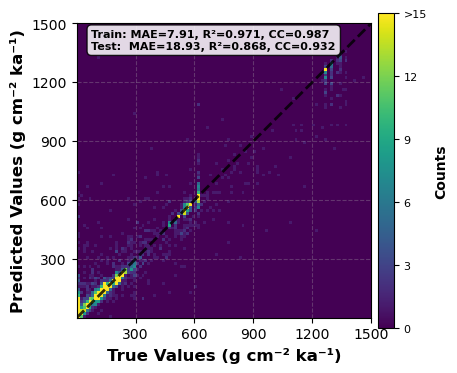

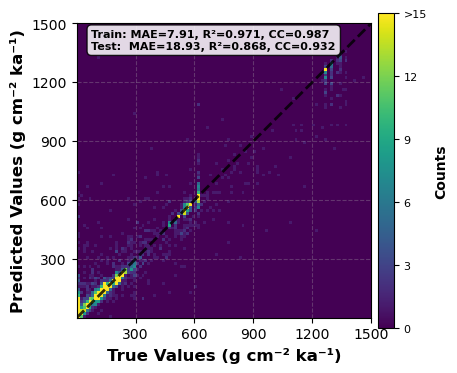

In [14]:
plot_predictions(train_labels, train_preds, test_labels, test_preds, model_name="random forests", n_estimators = 60)

In [15]:
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")

from os import walk  
from tqdm import tqdm  # Progress bar

feature_path = Path(Path() / str(project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_DO_men"))
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()

features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)

first_run = True

# Use tqdm for progress bar
for count, file in enumerate(tqdm(files, desc="Predicting on files")):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)

    # Perform multiple forward passes with dropout
    num_samples = 1  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    #with torch.no_grad():
    for i in range(num_samples):
        predictions = model.predict(features) #decoded, 

        # Store predictions for later averaging
        predictions_sum[i] = predictions.reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

Predicting on files:  13%|█▎        | 47/360 [00:06<00:42,  7.42it/s]


KeyboardInterrupt: 

In [14]:
print(features.shape)
print(X_mean.shape)

(25920, 110)
(110,)


## Generate Prediction Map: Random Forest

Generate prediction map for the entire globe using the trained Random Forest model.

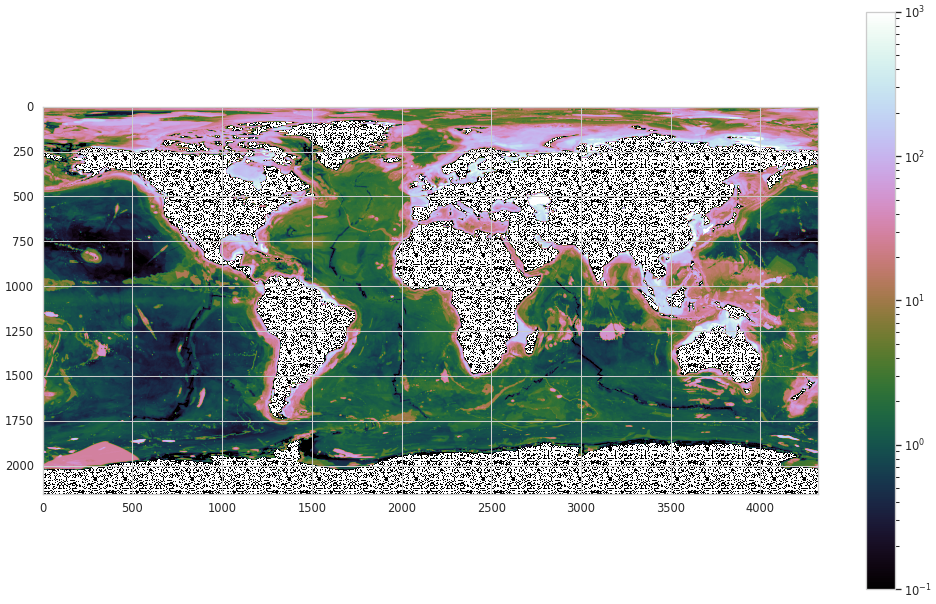

In [ ]:
#del features
gc.collect()
#"""    
land_file = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
prediction_map2[land_map] = 0
plt.imshow(prediction_map2 , norm=mcolors.LogNorm(vmin=1e-1, vmax=1e3), cmap="cubehelix")
cbar = plt.colorbar()
#"""

# Save prediction map
output_dir = project_root / "data" / "output" / "predictionmaps_SedRate" / "hyperparameter_optimization"
output_dir.mkdir(parents=True, exist_ok=True)
np.save(str(output_dir / "MAR_rf.npy"), prediction_map2)
print(f"Prediction map saved to: {output_dir / 'MAR_rf.npy'}")

## XGBoost

In [16]:
model_type = "xgboost"
n_estimators = 1000
model, training_mae, evaluation_mae, train_preds, test_preds = train_tree_based_model(
    train_features, train_labels, test_features, test_labels,
    model_type=model_type,  
    n_estimators=n_estimators
)

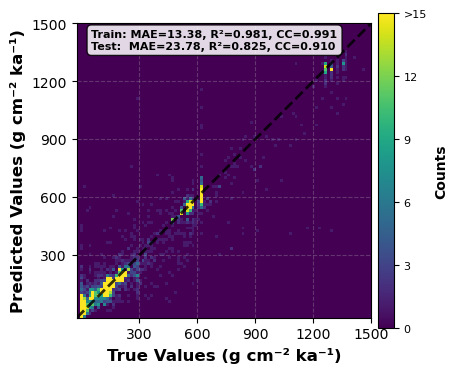

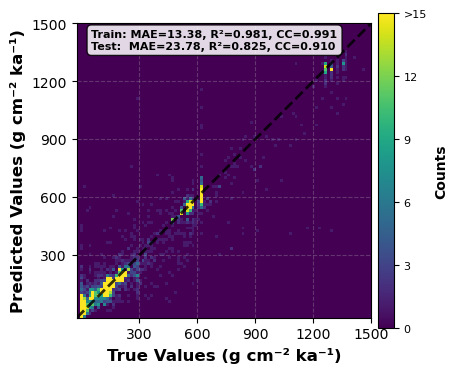

In [17]:
plot_predictions(train_labels, train_preds, test_labels, test_preds, model_name="xgboost", n_estimators=1000)

## Model Training: XGBoost

Train XGBoost model with different numbers of trees and evaluate performance.

In [18]:
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")



from os import walk  
feature_path = Path(Path() / str(project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_DO_men"))
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)


first_run = True
ii = 0
features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)


    # Perform multiple forward passes with dropout
    num_samples = 1  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    #with torch.no_grad():
    for i in range(num_samples):
        predictions = model.predict(features) #decoded, 

        # Store predictions for later averaging
        predictions_sum[i] = predictions.reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

    ii += 1
    print("Prediction " + str(ii) + " done!")

Prediction 1 done!
Prediction 2 done!
Prediction 3 done!
Prediction 4 done!
Prediction 5 done!
Prediction 6 done!
Prediction 7 done!
Prediction 8 done!
Prediction 9 done!
Prediction 10 done!
Prediction 11 done!
Prediction 12 done!
Prediction 13 done!
Prediction 14 done!
Prediction 15 done!
Prediction 16 done!
Prediction 17 done!
Prediction 18 done!
Prediction 19 done!
Prediction 20 done!
Prediction 21 done!
Prediction 22 done!
Prediction 23 done!
Prediction 24 done!
Prediction 25 done!
Prediction 26 done!
Prediction 27 done!
Prediction 28 done!
Prediction 29 done!
Prediction 30 done!
Prediction 31 done!
Prediction 32 done!
Prediction 33 done!
Prediction 34 done!
Prediction 35 done!
Prediction 36 done!
Prediction 37 done!
Prediction 38 done!
Prediction 39 done!
Prediction 40 done!
Prediction 41 done!
Prediction 42 done!
Prediction 43 done!
Prediction 44 done!
Prediction 45 done!
Prediction 46 done!
Prediction 47 done!
Prediction 48 done!
Prediction 49 done!
Prediction 50 done!
Predictio

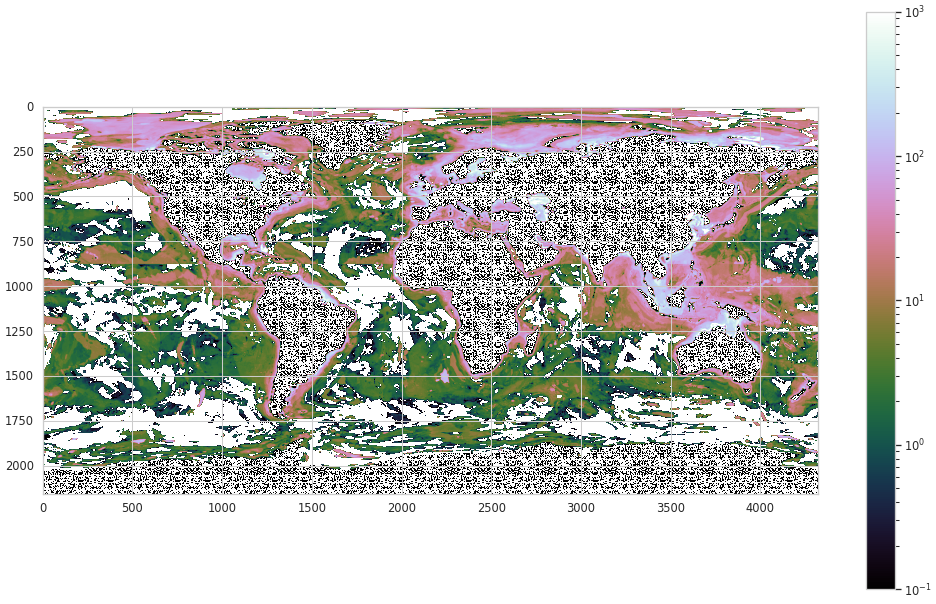

In [ ]:
#del features
gc.collect()
#"""    
land_file = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
prediction_map2[land_map] = 0
plt.imshow(prediction_map2 , norm=mcolors.LogNorm(vmin=1e-1 , vmax=1e3), cmap="cubehelix")
cbar = plt.colorbar()
#"""

# Save prediction map
output_dir = project_root / "data" / "output" / "predictionmaps_SedRate" / "hyperparameter_optimization"
output_dir.mkdir(parents=True, exist_ok=True)
np.save(str(output_dir / "MAR_xgboost.npy"), prediction_map2)
print(f"Prediction map saved to: {output_dir / 'MAR_xgboost.npy'}")

## Catboost

In [18]:
model_type = "catboost"
n_estimators = 1000
model, training_mae, evaluation_mae, train_preds, test_preds = train_tree_based_model(
    train_features, train_labels, test_features, test_labels,
    model_type=model_type, 
    n_estimators=n_estimators
)

## Model Training: CatBoost

Train CatBoost model with different numbers of trees and evaluate performance.

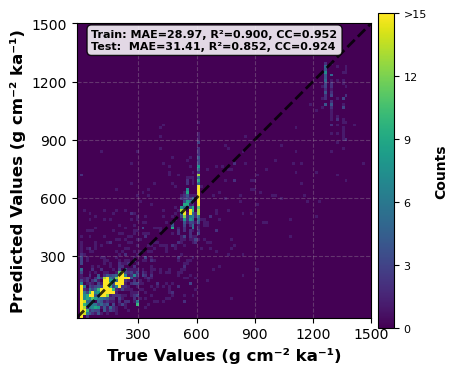

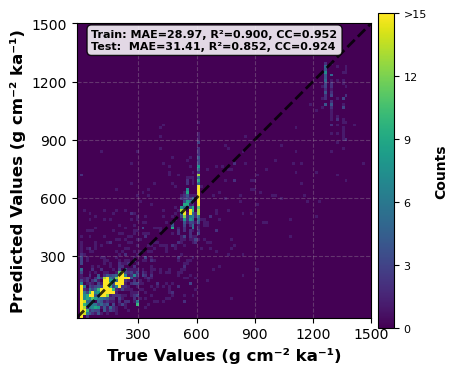

In [19]:
plot_predictions(train_labels, train_preds, test_labels, test_preds, model_name="catboost", n_estimators=1000)

In [22]:
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")



from os import walk  
feature_path = Path(Path() / str(project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_DO_men"))
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)


first_run = True
ii = 0
features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)


    # Perform multiple forward passes with dropout
    num_samples = 1  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    #with torch.no_grad():
    for i in range(num_samples):
        predictions = model.predict(features) #decoded, 

        # Store predictions for later averaging
        predictions_sum[i] = predictions.reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

    ii += 1
    print("Prediction " + str(ii) + " done!")

Prediction 1 done!
Prediction 2 done!
Prediction 3 done!
Prediction 4 done!
Prediction 5 done!
Prediction 6 done!
Prediction 7 done!
Prediction 8 done!
Prediction 9 done!
Prediction 10 done!
Prediction 11 done!
Prediction 12 done!
Prediction 13 done!
Prediction 14 done!
Prediction 15 done!
Prediction 16 done!
Prediction 17 done!
Prediction 18 done!
Prediction 19 done!
Prediction 20 done!
Prediction 21 done!
Prediction 22 done!
Prediction 23 done!
Prediction 24 done!
Prediction 25 done!
Prediction 26 done!
Prediction 27 done!
Prediction 28 done!
Prediction 29 done!
Prediction 30 done!
Prediction 31 done!
Prediction 32 done!
Prediction 33 done!
Prediction 34 done!
Prediction 35 done!
Prediction 36 done!
Prediction 37 done!
Prediction 38 done!
Prediction 39 done!
Prediction 40 done!
Prediction 41 done!
Prediction 42 done!
Prediction 43 done!
Prediction 44 done!
Prediction 45 done!
Prediction 46 done!
Prediction 47 done!
Prediction 48 done!
Prediction 49 done!
Prediction 50 done!
Predictio

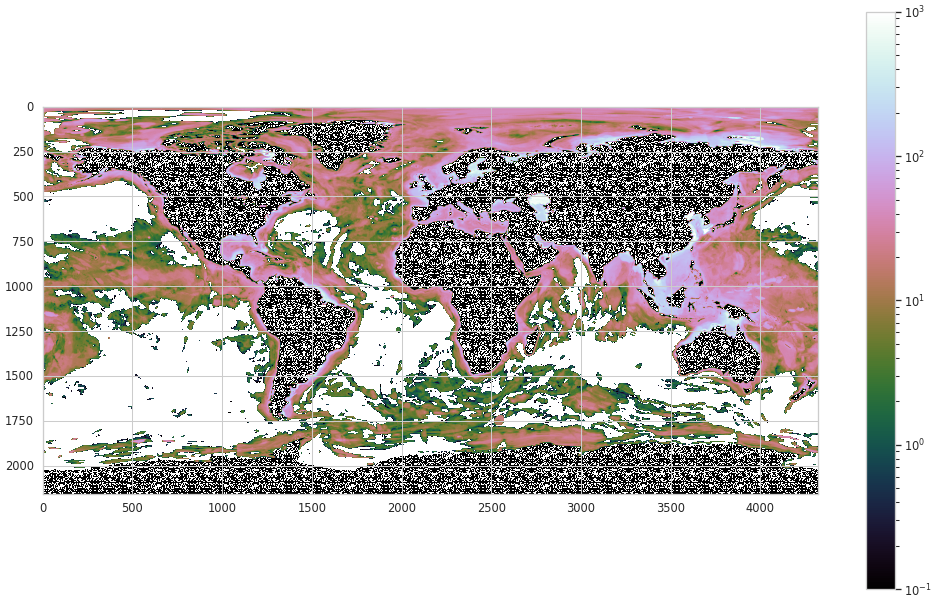

In [ ]:
#del features
gc.collect()
#"""    
land_file = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
prediction_map2[land_map] = 0
plt.imshow(prediction_map2 , norm=mcolors.LogNorm(vmin=1e-1, vmax=1e3), cmap="cubehelix")
cbar = plt.colorbar()
#"""

# Save prediction map
output_dir = project_root / "data" / "output" / "predictionmaps_SedRate" / "hyperparameter_optimization"
output_dir.mkdir(parents=True, exist_ok=True)
np.save(str(output_dir / "MAR_catboost.npy"), prediction_map2)
print(f"Prediction map saved to: {output_dir / 'MAR_catboost.npy'}")

## k nearest neighbours

## Model Training: K-Nearest Neighbors (KNN)

Train KNN model with different values of k (number of neighbors) and evaluate performance.

In [7]:
model, training_mae, evaluation_mae, train_preds, test_preds = train_knn(
        train_features, train_labels, test_features, test_labels,
        n_neighbors=9
    )

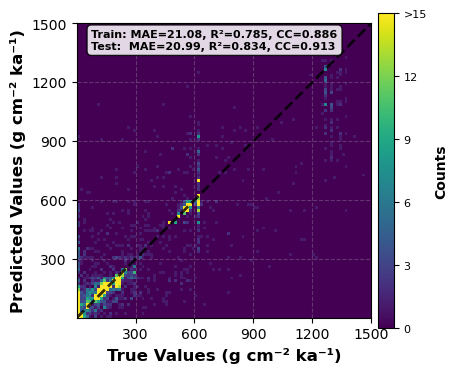

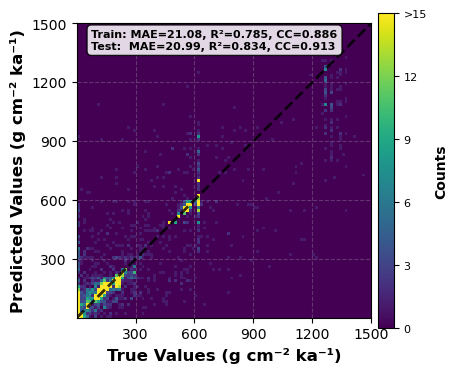

In [9]:
plot_predictions(
    train_labels, train_preds,
    test_labels, test_preds,
    model_name="KNN",
    n_estimators=9  # Here, we pass k instead of n_estimators
)

In [26]:
#os.chdir("/gxfs_work1/cau/sunms498/work/david/NN4SedRatePred/models/MLP/SedRate_MAR/models_torch/")


from os import walk  
feature_path = Path(Path() / str(project_root / "data" / "interim" / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_CS_men"))
X_mean = np.load(Path(feature_path / "features_mean.npy")).astype(float)
X_std = np.load(Path(feature_path / "features_std.npy")).astype(float)

#dataset_path = Path(Path().resolve().parents[2] / "Data" / "restrepoKNNsTOC" / "WorldFeaturesAll")#ChlorWorldFeatures
dataset_path = project_root / "data" / "interim" / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
files = []

for (dirpath, dirnames, filenames) in walk(dataset_path):
    files.extend(filenames)
    break

files.sort()


features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks

np.random.seed(42)


first_run = True
ii = 0
features = np.load(Path(dataset_path / files[0]))

chunk_shape = [6,4320] #360 chunks


first_run = True
ii = 0

for count, file in enumerate(files):
    features = np.load(Path(dataset_path / file))
    features = np.divide((features - X_mean), X_std)


    # Perform multiple forward passes with dropout
    num_samples = 1  # Adjust this based on your requirements
    predictions_sum = np.zeros((num_samples, chunk_shape[0], chunk_shape[1]))

    #with torch.no_grad():
    for i in range(num_samples):
        predictions = model.predict(features) #decoded, 

        # Store predictions for later averaging
        predictions_sum[i] = predictions.reshape(chunk_shape)

    # Average predictions over all samples
    predictions_avg = np.mean(predictions_sum, axis=0)
    predictions_var = np.var(predictions_sum, axis=0)

    if first_run:
        prediction_map2 = predictions_avg
        prediction_map2_var = predictions_var
        first_run = False
    else:
        prediction_map2 = np.append(prediction_map2, predictions_avg, axis=0)
        prediction_map2_var = np.append(prediction_map2_var, predictions_var, axis=0)

    ii += 1
    print("Prediction " + str(ii) + " done!")

Prediction 1 done!
Prediction 2 done!
Prediction 3 done!
Prediction 4 done!
Prediction 5 done!
Prediction 6 done!
Prediction 7 done!
Prediction 8 done!
Prediction 9 done!
Prediction 10 done!
Prediction 11 done!
Prediction 12 done!
Prediction 13 done!
Prediction 14 done!
Prediction 15 done!
Prediction 16 done!
Prediction 17 done!
Prediction 18 done!
Prediction 19 done!
Prediction 20 done!
Prediction 21 done!
Prediction 22 done!
Prediction 23 done!
Prediction 24 done!
Prediction 25 done!
Prediction 26 done!
Prediction 27 done!
Prediction 28 done!
Prediction 29 done!
Prediction 30 done!
Prediction 31 done!
Prediction 32 done!
Prediction 33 done!
Prediction 34 done!
Prediction 35 done!
Prediction 36 done!
Prediction 37 done!
Prediction 38 done!
Prediction 39 done!
Prediction 40 done!
Prediction 41 done!
Prediction 42 done!
Prediction 43 done!
Prediction 44 done!
Prediction 45 done!
Prediction 46 done!
Prediction 47 done!
Prediction 48 done!
Prediction 49 done!
Prediction 50 done!
Predictio

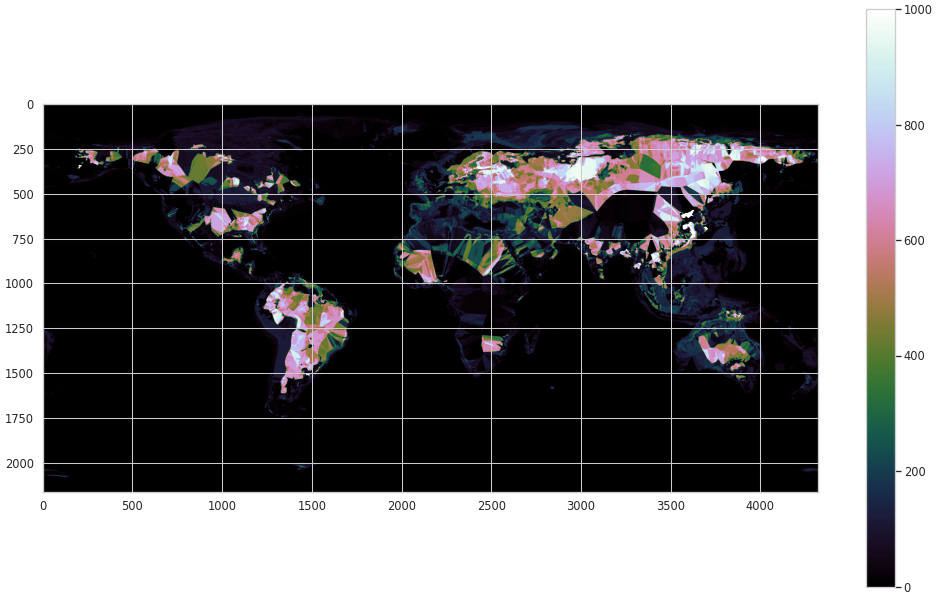

In [27]:
#del features
gc.collect()
#"""    
land_file = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1
#prediction_map2[land_map] = 0

#plt.figure(figsize=[25,15], dpi=200)
import matplotlib.colors as mcolors
prediction_map2 = np.rot90(np.rot90(np.fliplr(prediction_map2)))
plt.figure(figsize=[25, 15], dpi=50)
#prediction_map2[land_map] = 0
plt.imshow(prediction_map2 , vmin = 0, vmax = 1000, cmap="cubehelix")
cbar = plt.colorbar()
#"""


In [ ]:

# Save prediction map
output_dir = project_root / "data" / "output" / "predictionmaps_SedRate" / "hyperparameter_optimization"
output_dir.mkdir(parents=True, exist_ok=True)
np.save(str(output_dir / "MAR_knn.npy"), prediction_map2)
print(f"Prediction map saved to: {output_dir / 'MAR_knn.npy'}")